# Practice 2 · CNVs from reads to interpretation

**Call on hg19 → lift to hg38 → test expression in matched RNA → score with TESSERACT-CNV → read the tracks**

*Genomic Data Processing · Day 4 (10/15) · Understanding genetic variants · about 75 minutes*

> **All patients and controls in this practice are synthetic (computer-simulated). No real patient data are used.**
> The DNA reads were simulated from **real hg19 sequence**, and the CNVs were planted at **real loci** taken from public
> ClinVar and LOVD records. Because the loci are real, every result can be checked against public annotation.

**How to use this notebook.** Run the cells from top to bottom (Shift + Enter). Every step has the same four parts:

1. **Why this step** – the biological question, in plain words, with new terms defined.
2. **Code** – real shell commands (cells that start with `%%bash`) and short Python for tables and plots.
3. **Check** – prints a few numbers and stops with an `AssertionError` if something is wrong.
4. **What changed?** and **Your turn** – one question; click to reveal the answer.

## Step 0 · The clinical question, and why we use two genome builds  *(5 min)*

### Three (fictional) patients

| Sample | Who | Clinical features |
|---|---|---|
| **P1** | 6-year-old | congenital heart defect, speech delay |
| **P2** | 32-year-old | slowly progressive weakness of hands and feet, slowed nerve conduction |
| **P3** | 9-year-old | mild learning difficulties; parents not tested |
| **C1–C5** | unaffected controls | sequenced in the same way; used as the reference ("panel of normals") |

**Clinical question:** *Does each patient carry a copy-number variant that could explain the features, and how strong is the evidence?*

### Key words

* **Copy number (CN)** – how many copies of a piece of DNA a cell has. Normally **2** (one from each parent).
* **Copy-number variant (CNV)** – a stretch of DNA (here thousands to millions of bases) with more or fewer copies than normal.
  **Deletion** = loss (CN 1; CN 0 if both copies are gone). **Duplication** = gain (CN 3).
* **Read depth** – how many sequencing reads come from a region. More copies → more reads. This is our main signal.

### Why hg19 first, then hg38?

A **genome build** (assembly) is one version of the human reference sequence. **hg19** (= GRCh37, 2009) and **hg38**
(= GRCh38, 2013) contain almost the same DNA, but the **coordinates differ** and some difficult regions were rebuilt.
In this scenario the laboratory's DNA pipeline – like many older clinical pipelines and published data sets – still runs on
**hg19**. The matched RNA data, current gene annotation (MANE), ClinGen/ClinVar tracks and TESSERACT-CNV all use **hg38**.
So we **call CNVs on hg19, convert ("lift over") the calls to hg38, and check that conversion carefully** (Step 4).

### Why this design?

An earlier version of these slides called CNVs on a toy "hg19-like" contig and then switched to unrelated real CNVs for
TESSERACT, because TESSERACT reads **real hg38 annotation tracks**. Here the synthetic patients are simulated from real hg19
sequence with CNVs at real loci, so **the same CNV flows through every step**:

`reads (hg19) → depth → CNV call (hg19 BED) → liftover → hg38 BED → RNA (hg38 genes) → TESSERACT input (hg38) → tracks → evidence table`

### Files

| Folder | What is inside |
|---|---|
| `data/ref/` | practice reference: real hg19 sequence for three windows (chr22 18.0–23.0 Mb, chr17 14.6–15.7 Mb, chr4 69.0–69.8 Mb) inside full-length chromosomes that are otherwise `N`; the hg19→hg38 chain file |
| `data/fastq/` | paired-end reads (2 × 100 bp) for P1, P2, P3 and control C1 |
| `data/pon/` | panel of normals: fragment counts per 5-kb bin for controls C1–C5 |
| `data/truth/` | the CNVs we planted (open only in Step 3!) |
| `data/annotation/` | protein-coding genes: hg19 (RefSeq Select) and hg38 (MANE Select) |
| `data/rna/` | synthetic RNA-seq gene counts (hg38) for all 8 samples |
| `data/tracks_hg38/`, `data/tracks_hg19/` | public UCSC annotation tracks, pre-downloaded, with provenance |
| `scripts/` | the data generator, the track downloader and the plotting helpers |
| `results/` | what this notebook writes: `p2_results.json` and the slide figures |

### Time plan (≈ 75 min)

| Step | Topic | min | | Step | Topic | min |
|---|---|---|---|---|---|---|
| 0 | question, set-up | 5 | | 5 | RNA dosage | 9 |
| 1 | map reads (hg19) | 9 | | 6 | TESSERACT-CNV input | 6 |
| 2 | depth → copy-number signal | 12 | | 7 | read the tracks | 9 |
| 3 | segment and call (HMM) | 9 | | 8 | integrate the evidence | 4 |
| 4 | liftover hg19 → hg38 | 10 | | 9 | wrap-up | 2 |

In [1]:
# Step 0 · Set-up: imports, folders, tool versions, figure style
import os, sys, json, subprocess, time, math, datetime
import numpy as np
import pandas as pd
import pysam
import matplotlib
matplotlib.use("Agg")                  # figures are saved as PNG files and then displayed
import matplotlib.pyplot as plt
from IPython.display import Image, display

sys.path.insert(0, "scripts")
import p2_figures as F                 # slide-figure helpers (fonts, colours, layout)

T_START = time.time()
FIG = "results/figures"                # slide figures
NBFIG = "results/notebook_figures"     # small extra figures used only in this notebook
for d in ["data/bam", "data/results", FIG, NBFIG]:
    os.makedirs(d, exist_ok=True)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 70)
FONT = F.setup("fonts")

def first_line(cmd):
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    return ((r.stdout or "") + (r.stderr or "")).strip().splitlines()[0]

VERSIONS = {
    "minimap2": first_line("minimap2 --version"),
    "samtools": first_line("samtools --version").split()[-1],
    "htslib (bgzip)": first_line("bgzip --version").split()[-1],
    "CrossMap": first_line("CrossMap --version").split()[-1],
    "python": sys.version.split()[0], "pysam": pysam.__version__, "numpy": np.__version__,
    "pandas": pd.__version__, "matplotlib": matplotlib.__version__,
}
print(pd.Series(VERSIONS).to_string())
print("figure font:", FONT)

minimap2          2.31-r1302
samtools                1.24
htslib (bgzip)          1.24
CrossMap               0.7.3
python               3.12.15
pysam                 0.24.1
numpy                  2.5.4
pandas                 3.0.6
matplotlib            3.11.2
figure font: SUIT


In [2]:
# CHECK · all input files are present and the reference has real hg19 chromosome lengths
needed = ["data/ref/hg19_cnv_windows.fa.gz", "data/ref/hg19_cnv_windows.fa.gz.fai", "data/ref/hg19_cnv_windows.fa.gz.gzi",
          "data/ref/windows_hg19.bed", "data/ref/hg19ToHg38.over.chain.gz",
          *[f"data/fastq/{s}_R{r}.fastq.gz" for s in ["P1", "P2", "P3", "C1"] for r in (1, 2)],
          "data/pon/pon_bincounts_hg19_5kb.tsv.gz", "data/truth/planted_cnvs_hg19.tsv",
          "data/annotation/genes_hg19_refseqselect_windows.tsv", "data/annotation/genes_hg38_mane_select.tsv.gz",
          "data/rna/counts_hg38_mane.tsv.gz", "data/rna/samples.tsv", "data/tracks_hg38/provenance_tracks_hg38.json"]
missing = [f for f in needed if not os.path.exists(f)]
assert not missing, f"missing files: {missing}"

fai = pd.read_csv("data/ref/hg19_cnv_windows.fa.gz.fai", sep="\t", header=None, usecols=[0, 1], names=["chrom", "length"])
windows = pd.read_csv("data/ref/windows_hg19.bed", sep="\t", header=None, names=["chrom", "start", "end", "name"])
assert dict(zip(fai.chrom, fai.length)) == {"chr4": 191154276, "chr17": 81195210, "chr22": 51304566}
print(windows.assign(size_Mb=(windows.end - windows.start) / 1e6).to_string(index=False))
print(f"real sequence: {(windows.end - windows.start).sum() / 1e6:.1f} Mb of {fai.length.sum() / 1e6:.0f} Mb (the rest is N)")
samples_info = pd.read_csv("data/rna/samples.tsv", sep="\t")
print(samples_info[["sample", "role", "age", "phenotype"]].to_string(index=False))

chrom    start      end                      name  size_Mb
chr22 18000000 23000000        22q11.2_(LCR22A-F)      5.0
chr17 14600000 15700000 17p12_(PMP22_/_CMT1A-REP)      1.1
 chr4 69000000 69800000          4q13.2_(UGT2B17)      0.8
real sequence: 6.9 Mb of 324 Mb (the rest is N)
sample    role  age                                                               phenotype
    P1 patient    6                       congenital heart defect; speech delay (fictional)
    P2 patient   32 slowly progressive distal weakness; slowed nerve conduction (fictional)
    P3 patient    9                mild learning difficulties; parents untested (fictional)
    C1 control   35                                          unaffected control (fictional)
    C2 control   41                                          unaffected control (fictional)
    C3 control   29                                          unaffected control (fictional)
    C4 control   52                                          unaffected 

**What changed?** Nothing yet – we only checked the inputs. The reference has the true hg19 lengths, so every coordinate
we report is a genuine hg19 coordinate, even though only 6.9 Mb of real sequence is present.

**Your turn.** Why is it useful that the reference keeps full-length chromosomes (filled with `N`) instead of three short
contigs called, for example, `win1`, `win2`, `win3`?

<details><summary>Answer</summary>

Because positions stay real: `chr22:19,750,000` in our BAM is the same base as in any hg19 genome browser, ClinVar record or
chain file. With short contigs, every position would need to be converted first, and the hg19→hg38 chain file (which uses
real chromosome names and positions) could not be applied directly. Reads cannot map to `N`, so the extra length costs
almost nothing.
</details>

## Step 1 · Map the DNA reads to hg19  *(9 min)*

### Why this step

Each **read pair** in a FASTQ file is a short piece of a person's DNA: 100 letters from each end of a ~350-bp
**fragment**. The FASTQ file does **not** say where in the genome a read came from. **Mapping** (alignment) finds the best
matching place in the reference genome. Only after mapping can we ask "*how many fragments came from this region?*" –
the basis of CNV calling.

New terms:

* **BAM** – a compressed table with one row per read: chromosome, position, mapping quality, flags, sequence.
* **Read group (`@RG`)** – a label in every read that says which sample (`SM`) and library it came from. Essential when
  files are merged.
* **MAPQ (mapping quality)** – how sure the mapper is about the position: 0 = "could equally be somewhere else",
  60 = unique. Reads from **segmental duplications** (long, near-identical copies of DNA, such as the LCR22 repeats in
  22q11.2) get **low MAPQ**, because they fit several places equally well.
* **Duplicates** – several reads from the same original DNA fragment (copies made by PCR or by the sequencer). They would
  inflate depth, so we **mark** them (flag 1024) and ignore them later; we do not delete them.

The pipeline: `minimap2 -ax sr` (short-read preset) → `samtools fixmate -m` (adds mate information that duplicate marking
needs) → `samtools sort` (by position) → `samtools markdup` → `samtools index` (fast access to any region).

In [3]:
%%bash
# Step 1 · map each sample (about 5 seconds per sample)
set -euo pipefail
REF=data/ref/hg19_cnv_windows.fa.gz
for S in P1 P2 P3 C1; do
  minimap2 -ax sr -t 4 -R "@RG\tID:${S}\tSM:${S}\tPL:ILLUMINA\tLB:${S}_lib1" \
      $REF data/fastq/${S}_R1.fastq.gz data/fastq/${S}_R2.fastq.gz 2> data/bam/${S}.minimap2.log \
    | samtools fixmate -m - - \
    | samtools sort -o data/bam/${S}.sorted.bam - 2> /dev/null
  samtools markdup -s data/bam/${S}.sorted.bam data/bam/${S}.bam 2> data/bam/${S}.markdup.log
  samtools index data/bam/${S}.bam
  rm data/bam/${S}.sorted.bam
  echo "${S}: data/bam/${S}.bam  ($(samtools view -c data/bam/${S}.bam) reads)"
done
samtools view -H data/bam/P1.bam | grep "^@RG"

P1: data/bam/P1.bam  (187714 reads)
P2: data/bam/P2.bam  (199367 reads)
P3: data/bam/P3.bam  (209823 reads)
C1: data/bam/C1.bam  (213262 reads)
@RG	ID:P1	SM:P1	PL:ILLUMINA	LB:P1_lib1


In [4]:
# CHECK · flagstat (mapping and duplicates) and mean depth over the three windows
def flagstat(bam):
    out = subprocess.run(["samtools", "flagstat", "-O", "tsv", bam], capture_output=True, text=True).stdout
    return {line.split("\t")[2]: line.split("\t")[0] for line in out.strip().splitlines()}

def mean_depth(bam):
    tot_bases = tot_len = 0
    for c, s0, e in windows[["chrom", "start", "end"]].itertuples(index=False):
        out = subprocess.run(["samtools", "coverage", "-H", "-r", f"{c}:{s0 + 1}-{e}", bam], capture_output=True, text=True).stdout
        depth = float(out.split("\t")[6])
        tot_bases += depth * (e - s0); tot_len += e - s0
    return tot_bases / tot_len

qc = []
for s in ["P1", "P2", "P3", "C1"]:
    f = flagstat(f"data/bam/{s}.bam")
    total = int(f["total (QC-passed reads + QC-failed reads)"])
    qc.append({"sample": s, "read pairs": int(f["read1"]), "% mapped": float(f["mapped %"].rstrip("%")),
               "% properly paired": float(f["properly paired %"].rstrip("%")),
               "% duplicates": round(100 * int(f["duplicates"]) / total, 2),
               "mean depth (x)": round(mean_depth(f"data/bam/{s}.bam"), 2)})
qc = pd.DataFrame(qc).set_index("sample")
print(qc.to_string())
assert (qc["% mapped"] > 99).all() and qc["% duplicates"].between(1.5, 5).all()

        read pairs  % mapped  % properly paired  % duplicates  mean depth (x)
sample                                                                       
P1           93857     99.97              99.93          2.78            2.64
P2           99683     99.96              99.92          2.78            2.81
P3          104911     99.96              99.91          2.74            2.96
C1          106631     99.96              99.92          2.79            3.00


In [5]:
%%bash
# MAPQ is low in segmental duplications: the same 100-kb region counted with and without a MAPQ filter
for R in "LCR22A (segmental duplication) chr22:18700001-18800000" "unique sequence chr22:19700001-19800000"; do
  REG=${R##* }
  echo "${R}:  all reads $(samtools view -c data/bam/C1.bam $REG)   MAPQ>=20 $(samtools view -c -q 20 data/bam/C1.bam $REG)"
done

LCR22A (segmental duplication) chr22:18700001-18800000:  all reads 3187   MAPQ>=20 1025
unique sequence chr22:19700001-19800000:  all reads 2385   MAPQ>=20 2383


In [6]:
# CHECK · MAPQ inside vs outside segmental duplications (hg19 UCSC genomicSuperDups), control C1
sd19 = pd.read_csv("data/tracks_hg19/genomicSuperDups_hg19_windows.tsv.gz", sep="\t")

def merge_intervals(starts, ends):
    out = []
    for a, b in sorted(zip(starts, ends)):
        if out and a <= out[-1][1]:
            out[-1][1] = max(out[-1][1], b)
        else:
            out.append([a, b])
    return np.array(out, dtype=np.int64).reshape(-1, 2)

def in_intervals(pos, iv):
    i = np.searchsorted(iv[:, 0], pos, side="right") - 1
    return (i >= 0) & (pos < iv[np.clip(i, 0, None), 1])

SEGDUP19 = {c: merge_intervals(sd19.chromStart[sd19.chrom == c], sd19.chromEnd[sd19.chrom == c]) for c in windows.chrom}
mq_in, mq_out = [], []
with pysam.AlignmentFile("data/bam/C1.bam") as bam:
    for c, s0, e in windows[["chrom", "start", "end"]].itertuples(index=False):
        reads = [(r.reference_start, r.mapping_quality) for r in bam.fetch(c, s0, e)
                 if not (r.is_unmapped or r.is_secondary or r.is_supplementary)]
        pos, mq = np.array(reads).T
        inside = in_intervals(pos, SEGDUP19[c])
        mq_in.append(mq[inside]); mq_out.append(mq[~inside])
mq_in, mq_out = np.concatenate(mq_in), np.concatenate(mq_out)
mapq_table = pd.DataFrame({"reads": [len(mq_in), len(mq_out)],
                           "% MAPQ < 20": [round(100 * np.mean(mq_in < 20), 1), round(100 * np.mean(mq_out < 20), 1)],
                           "median MAPQ": [np.median(mq_in), np.median(mq_out)]},
                          index=["inside segmental duplications", "unique sequence"])
print(mapq_table.to_string())
assert mapq_table.loc["inside segmental duplications", "% MAPQ < 20"] > 10 * mapq_table.loc["unique sequence", "% MAPQ < 20"]
view_c = lambda args: int(subprocess.run(f"samtools view -c {args}", shell=True, capture_output=True, text=True).stdout)
lcr_demo = {"LCR22A chr22:18700001-18800000": [view_c("data/bam/C1.bam chr22:18700001-18800000"), view_c("-q 20 data/bam/C1.bam chr22:18700001-18800000")],
            "unique chr22:19700001-19800000": [view_c("data/bam/C1.bam chr22:19700001-19800000"), view_c("-q 20 data/bam/C1.bam chr22:19700001-19800000")]}

                                reads  % MAPQ < 20  median MAPQ
inside segmental duplications   56234         37.5         50.0
unique sequence                156946          0.2         60.0


**What changed?** FASTQ (reads without positions) → BAM (every read has a chromosome, position, MAPQ and flags; sorted;
indexed; duplicates flagged but kept). You verified it with `flagstat` (> 99.9 % mapped, ≈ 3 % duplicates) and by
showing that reads in segmental duplications often have MAPQ < 20.

> **Note on this practice reference.** Only three windows of real sequence are present. Segmental duplications whose
> partner copies lie *inside* a window (the LCR22s on chr22) behave as in a real genome; copies whose partner lies elsewhere
> in the genome (for example around UGT2B17) look unique here. A whole-genome analysis would show more low-MAPQ reads.

**Your turn.** Run `samtools view data/bam/P1.bam chr22:19750001-19750100 | head -2` in a new cell (start it with `!`).
Which columns hold the chromosome, the position and the MAPQ?

<details><summary>Answer</summary>

Column 3 = chromosome (`RNAME`), column 4 = leftmost position, 1-based (`POS`), column 5 = mapping quality (`MAPQ`).
Column 2 is the FLAG (a number that encodes paired, mapped, duplicate …; decode it with `samtools flags <number>`).
At the end of the row you will find the `RG:Z:P1` tag added by `-R`.
</details>

## Step 2 · From depth to a copy-number signal  *(12 min)*

### Why this step

If a region has **one** copy instead of two, we expect about **half** as many DNA fragments from it; with **three** copies,
about **1.5 times** as many. But raw counts also change for reasons that have nothing to do with copy number:

1. **Library size** – one sample was simply sequenced more than another.
2. **Local properties of the genome** – GC content (the fraction of G and C bases) and mappability change how many reads a
   region gets. These effects are the **same in every sample processed in the same way**.

So we (1) divide by the library size and (2) divide by a **panel of normals** (PON): the median of five controls processed
with exactly the same commands. Whatever is left should be copy number.

New terms:

* **Bin** – a fixed 5-kb window. We count fragments per bin.
* **Per million** – fragments in a bin ÷ all counted fragments × 1,000,000 (the same idea as CPM in RNA-seq, Step 5).
* **Ratio** and **log2 ratio** – sample ÷ panel. log2 makes losses and gains symmetric:
  log2(2/2) = **0**, log2(1/2) = **−1**, log2(3/2) ≈ **+0.58**, log2(0/2) = −∞ (we show it as −3).
* **Masking** – removing bins we cannot trust: assembly gaps, bins where even the controls have few reliable reads
  (segmental duplications, MAPQ < 20) and bins where the controls disagree with each other.

We count each fragment **once**, at its midpoint, using only reads that are properly paired, primary, not duplicates and
have **MAPQ ≥ 20**.

In [7]:
# Step 2a · count DNA fragments in 5-kb bins (same code as scripts/cnvlib.py, used to build the panel of normals)
pon = pd.read_csv("data/pon/pon_bincounts_hg19_5kb.tsv.gz", sep="\t")
bins = pon[["chrom", "start", "end", "gc", "n_frac"]].copy()        # 0-based starts (BED convention)
MIN_MAPQ = 20

def count_fragments_in_bins(bam_path, bins, min_mapq=MIN_MAPQ):
    # One count per DNA fragment, at its midpoint, using the LEFT read of each properly paired fragment
    # (template length > 0). Skips unmapped, secondary, supplementary, QC-fail and duplicate reads, and MAPQ < min_mapq.
    counts = np.zeros(len(bins), dtype=np.int64)
    with pysam.AlignmentFile(bam_path) as bam:
        for chrom, grp in bins.groupby("chrom", sort=False):
            first = grp.index[0]
            w0, w1 = int(grp.start.min()), int(grp.end.max())
            size = int(grp.end.iloc[0] - grp.start.iloc[0])
            for r in bam.fetch(chrom, w0, w1):
                if (r.is_unmapped or r.is_secondary or r.is_supplementary or r.is_qcfail
                        or r.is_duplicate or not r.is_proper_pair):
                    continue
                if r.template_length <= 0 or r.mapping_quality < min_mapq:
                    continue
                mid = r.reference_start + r.template_length // 2
                if w0 <= mid < w1:
                    counts[first + (mid - w0) // size] += 1
    return counts

counts = pd.DataFrame({s: count_fragments_in_bins(f"data/bam/{s}.bam", bins) for s in ["P1", "P2", "P3", "C1"]})
print(f"{len(bins):,} bins of {int(bins.end.iloc[0] - bins.start.iloc[0]):,} bp")
print(counts.sum().rename("fragments counted").to_string())

1,380 bins of 5,000 bp
P1    81747
P2    87019
P3    92799
C1    93049


In [8]:
%%bash
# The same filters with samtools (flags 3332 = unmapped + secondary + duplicate + supplementary)
samtools flags 3332
for S in P2 C1; do
  echo "${S}  chr17:15,145,001-15,150,000 (inside the PMP22 gene): $(samtools view -c -q 20 -f 2 -F 3332 data/bam/${S}.bam chr17:15145001-15150000) reads"
done

0xd04	3332	UNMAP,SECONDARY,DUP,SUPPLEMENTARY
P2  chr17:15,145,001-15,150,000 (inside the PMP22 gene): 163 reads
C1  chr17:15,145,001-15,150,000 (inside the PMP22 gene): 131 reads


In [9]:
# CHECK · your C1 is identical to the C1 column of the panel of normals (same commands -> same numbers)
same = np.array_equal(counts["C1"].values, pon["C1"].values)
print("C1 (you) == C1 (panel):", same, "| fragments", int(counts.C1.sum()), "vs", int(pon.C1.sum()))
assert same, "C1 differs from the panel: check the mapping commands in Step 1 and MIN_MAPQ"
b = bins.index[(bins.chrom == "chr17") & (bins.start == 15145000)][0]
pmp22_bin_example = {s: {"fragments": int(counts.loc[b, s]),
                          "reads_samtools": view_c(f"-q 20 -f 2 -F 3332 data/bam/{s}.bam chr17:15145001-15150000")} for s in ["P2", "C1"]}
print("fragments in chr17:15,145,001-15,150,000 ->", {s: v["fragments"] for s, v in pmp22_bin_example.items()},
      "(samtools counted READS; each fragment has two reads)")

C1 (you) == C1 (panel): True | fragments 93049 vs 93049
fragments in chr17:15,145,001-15,150,000 -> {'P2': 79, 'C1': 63} (samtools counted READS; each fragment has two reads)


In [10]:
# Step 2b · library size -> ratio to the panel -> log2 -> mask -> centre
CONTROLS = ["C1", "C2", "C3", "C4", "C5"]

def per_million(x):
    # library-size normalisation: fragments per million counted fragments
    return x / x.sum() * 1e6

pon_pm = pon[CONTROLS].apply(per_million)
panel = pon_pm.median(axis=1)                    # the panel of normals: median of the five controls, per bin
pm = counts.apply(per_million)

# Masks: bins we do not trust
typical = panel[bins.n_frac <= 0.1].median()
loo = pd.DataFrame({c: np.log2((pon_pm[c] + 1) / (pon_pm.drop(columns=c).median(axis=1) + 1)) for c in CONTROLS})
robust_sd = 1.4826 * loo.sub(loo.median(axis=1), axis=0).abs().median(axis=1)   # spread of the controls (robust)
mask_gap = bins.n_frac > 0.10                                  # more than 10% N: assembly gap
mask_low = (panel < 0.5 * typical) & ~mask_gap                 # few MAPQ>=20 reads even in controls
mask_var = (robust_sd > 0.60) & ~mask_gap & ~mask_low          # controls disagree (> ~3x the usual control noise)
masked = mask_gap | mask_low | mask_var

# Ratio to the panel. C1 is compared with the OTHER four controls (it is part of the panel itself).
ratio = pd.DataFrame({s: (pm[s] + 1) / (panel + 1) for s in ["P1", "P2", "P3"]})
ratio["C1"] = (pm["C1"] + 1) / (pon_pm.drop(columns="C1").median(axis=1) + 1)
log2r = np.log2(ratio)

def copy_neutral_level(x, half_width=0.3, n_iter=3):
    # Centre of the biggest peak of log2 ratios (= the copy-neutral level). Start at the top of a smoothed
    # histogram, then take the median of all bins within +/- 0.3 of it (three times).
    x = np.asarray(x, float)
    x = x[np.isfinite(x)].clip(-3, 3)
    grid = np.arange(-1.5, 1.5001, 0.01)
    dens = np.exp(-0.5 * ((grid[:, None] - x[None, :]) / 0.1) ** 2).sum(axis=1)
    c = float(grid[np.argmax(dens)])
    for _ in range(n_iter):
        c = float(np.median(x[np.abs(x - c) <= half_width]))
    return c

offset = {s: copy_neutral_level(log2r.loc[~masked, s]) for s in log2r}
log2c = pd.DataFrame({s: (log2r[s] - offset[s]).clip(-3, 3) for s in log2r})   # centred; CN 0 shows as -3
print("masked bins:", {"gap": int(mask_gap.sum()), "low panel depth": int(mask_low.sum()),
                       "variable controls": int(mask_var.sum()), "total": int(masked.sum()), "of": len(bins)})
print("centring offsets (log2):", {k: round(v, 3) for k, v in offset.items()})

masked bins: {'gap': 21, 'low panel depth': 166, 'variable controls': 6, 'total': 193, 'of': 1380}
centring offsets (log2): {'P1': 0.269, 'P2': 0.007, 'P3': 0.166, 'C1': -0.011}


**Why centre?** Library-size normalisation assumes that most of the genome is copy-neutral. Our mini-genome is only 6.9 Mb,
and P1's 2.5-Mb deletion removes about 18 % of P1's fragments – so after dividing by P1's total, every *normal* bin looks
too high (log2 ≈ +0.27). In a real 3,000-Mb genome a 2.5-Mb deletion barely changes the total. We fix it by moving the
biggest peak of the log2 values (the copy-neutral bins) to 0 – CNVkit offers the same idea as a "mode" centring option.

In [11]:
# CHECK · masks are where we expect them, GC bias cancels, worked examples for single bins
mid = ((bins.start + bins.end) // 2).values
in_sd = np.zeros(len(bins), bool)
for c in windows.chrom:
    sel = (bins.chrom == c).values
    in_sd[sel] = in_intervals(mid[sel], SEGDUP19[c])
print(f"low-depth masked bins whose centre lies in a segmental duplication: {in_sd[mask_low].mean():.0%}"
      f" (all bins: {in_sd.mean():.0%})")
ok = ~masked.values
gc_group = pd.qcut(bins.gc[ok], 10, labels=False)                     # 10 groups of bins with similar GC
med_raw = pm.C1[ok].groupby(gc_group).median()
med_ratio = (2 ** log2c.C1[ok]).groupby(gc_group).median()
gc_effect_raw = float((med_raw.max() - med_raw.min()) / pm.C1[ok].median())
gc_effect_ratio = float(med_ratio.max() - med_ratio.min())
print(f"GC effect in C1 (range of the 10 GC-group medians): raw depth {gc_effect_raw:.0%}  ->  ratio to panel {gc_effect_ratio:.0%}")
print(f"spread of C1 log2 ratios in unmasked bins: SD = {log2c.C1[ok].std():.2f}")
assert in_sd[mask_low].mean() > 0.8 and gc_effect_raw > 0.15 and gc_effect_ratio < 0.08

# one bin in the middle of a gene, in a sample with and without a CNV there
EXAMPLES = [("P2", "chr17", 15150000, "PMP22 duplication (CN 3)", np.log2(3 / 2)),
            ("P1", "chr22", 19755000, "TBX1, 22q11.2 deletion (CN 1)", -1.0),
            ("P3", "chr4", 69415000, "UGT2B17, both copies deleted (CN 0)", -np.inf),
            ("C1", "chr17", 15150000, "the same PMP22 bin in control C1 (CN 2)", 0.0)]
rows = []
for s, c, st, what, expected in EXAMPLES:
    i = bins.index[(bins.chrom == c) & (bins.start == st)][0]
    assert not masked[i], f"{c}:{st} is masked"
    raw = int(counts.loc[i, s]) if s in counts else int(pon.loc[i, s])
    rows.append({"sample": s, "bin (hg19, 1-based)": f"{c}:{st + 1:,}-{st + 5000:,}", "what": what,
                 "raw": raw, "per million": round(pm.loc[i, s], 1),
                 "panel": round(panel[i], 1), "ratio": round(ratio.loc[i, s], 2),
                 "log2": round(log2r.loc[i, s], 2), "log2 centred": round(log2c.loc[i, s], 2),
                 "expected": "−∞ (−3)" if np.isinf(expected) else round(expected, 2)})
worked_examples = pd.DataFrame(rows)
display(worked_examples)
print("One bin is noisy (SD of a CN-2 bin = 0.19): the HMM in Step 3 combines many neighbouring bins.")

low-depth masked bins whose centre lies in a segmental duplication: 97% (all bins: 28%)
GC effect in C1 (range of the 10 GC-group medians): raw depth 39%  ->  ratio to panel 5%
spread of C1 log2 ratios in unmasked bins: SD = 0.19


,sample,"bin (hg19, 1-based)",what,raw,per million,panel,ratio,log2,log2 centred,expected
0,P2,"chr17:15,150,001-15,155,000",PMP22 duplication (CN 3),122,1402.0,841.5,1.67,0.74,0.73,0.58
1,P1,"chr22:19,755,001-19,760,000","TBX1, 22q11.2 deletion (CN 1)",43,526.0,758.8,0.69,-0.53,-0.80,-1.0
2,P3,"chr4:69,415,001-69,420,000","UGT2B17, both copies deleted (CN 0)",0,0.0,696.6,0.00,-9.45,-3.00,−∞ (−3)
3,C1,"chr17:15,150,001-15,155,000",the same PMP22 bin in control C1 (CN 2),69,741.5,841.5,0.88,-0.18,-0.17,0.0


One bin is noisy (SD of a CN-2 bin = 0.19): the HMM in Step 3 combines many neighbouring bins.


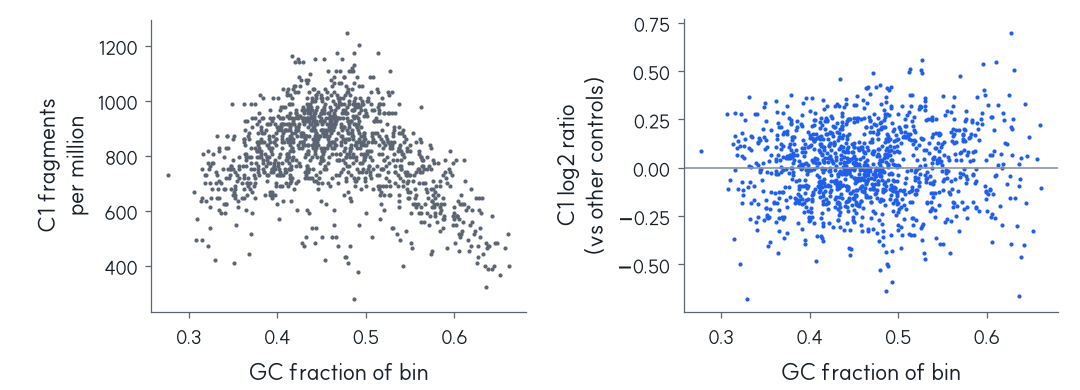

In [12]:
# A quick picture of the GC effect in control C1 (raw depth depends on GC; the log2 ratio does not)
fig, axs = plt.subplots(1, 2, figsize=(7.2, 2.6), gridspec_kw=dict(wspace=0.42, left=0.14, right=0.98, bottom=0.2, top=0.95))
axs[0].scatter(bins.gc[ok], pm.C1[ok], s=4, color=F.GRAY, lw=0)
axs[0].set_xlabel("GC fraction of bin"); axs[0].set_ylabel("C1 fragments\nper million")
axs[1].scatter(bins.gc[ok], log2c.C1[ok], s=4, color=F.BLUE, lw=0)
axs[1].axhline(0, color=F.LGRAY, lw=0.8)
axs[1].set_xlabel("GC fraction of bin"); axs[1].set_ylabel("C1 log2 ratio\n(vs other controls)")
fig.savefig(f"{NBFIG}/step2_gc_effect.png", dpi=150); plt.close(fig)
display(Image(f"{NBFIG}/step2_gc_effect.png"))

**What changed?** Integer counts per bin → normalised, centred **log2 ratios**, with unreliable bins masked. The GC trend
that is visible in raw depth disappears after dividing by the panel, because every sample has the same GC bias. Normal
regions sit near 0, P1's deletion near −1, the PMP22 duplication in P2 near +0.58 and the UGT2B17 bins in P3 at the floor.

**Your turn.** Why do we use the **median** of the five controls, not the mean? (Hint: control C2 carries a common
UGT2B17 deletion.)

<details><summary>Answer</summary>

The median ignores one unusual control. C2 has only one copy of UGT2B17; with the mean, the panel value would be ~10 %
too low there and every sample would look slightly "gained" at UGT2B17. Controls are **not CNV-free**: common CNVs exist
in healthy people, which is why real panels use many controls and robust statistics.
</details>

## Step 3 · Segment and call CNVs with a small HMM  *(9 min)*

### Why this step

Single bins are noisy. We need to decide **where the copy number changes** and which neighbouring bins belong together.

A **hidden Markov model (HMM)** does this in a transparent way:

* the **hidden state** of each bin is its true copy number (CN 0, 1, 2, 3 or 4);
* what we **observe** is the noisy log2 ratio. For each state we expect a value (−3 for CN 0 because we clipped there,
  −1, 0, +0.58, +1) with noise **σ** measured in the controls (fewer copies → fewer reads → a little more noise);
* the model prefers to **stay** in the same state from one bin to the next (switching has probability 1 in 100), so a
  single odd bin is ignored but several consecutive odd bins are not;
* the **Viterbi algorithm** finds the single most likely sequence of states.

We then merge runs of the same state into **segments**, keep segments with at least 3 unmasked bins (15 kb) and write them
as a BED file on hg19. Finally – and only now – we open the truth file and compare.

In [13]:
# Step 3 · HMM parameters and the Viterbi algorithm (about 20 lines)
CN_STATES = np.array([0, 1, 2, 3, 4])
EXPECTED_LOG2 = np.array([-3.0, -1.0, 0.0, np.log2(3 / 2), 1.0])   # CN 0 is really -infinity; we clipped at -3
ctrl_log2 = loo[~masked].values.ravel()                              # control-vs-control log2 ratios
SIGMA0 = 1.4826 * np.median(np.abs(ctrl_log2 - np.median(ctrl_log2)))   # noise of a CN-2 bin (robust SD)
SIGMA = np.array([0.6] + [SIGMA0 * np.sqrt(2 / k) for k in CN_STATES[1:]])
P_SWITCH = 1e-2        # probability of a copy-number change between neighbouring bins (see INSTRUCTOR_NOTES)
MIN_BINS = 3           # smallest CNV we report: 3 unmasked bins = 15 kb
LOCUS = {"chr22": "22q11", "chr17": "PMP22", "chr4": "UGT2B17"}

def viterbi(x):
    n, K = len(x), len(CN_STATES)
    log_emit = -0.5 * ((x[:, None] - EXPECTED_LOG2[None, :]) / SIGMA[None, :]) ** 2 - np.log(SIGMA)[None, :]
    log_trans = np.full((K, K), np.log(P_SWITCH / (K - 1)))
    np.fill_diagonal(log_trans, np.log(1 - P_SWITCH))
    score = np.log(np.where(CN_STATES == 2, 1 - P_SWITCH, P_SWITCH / (K - 1))) + log_emit[0]
    back = np.zeros((n, K), dtype=int)
    for i in range(1, n):
        cand = score[:, None] + log_trans            # rows: previous state, columns: next state
        back[i] = cand.argmax(axis=0)
        score = cand.max(axis=0) + log_emit[i]
    path = np.zeros(n, dtype=int)
    path[-1] = score.argmax()
    for i in range(n - 1, 0, -1):                     # trace back the best path
        path[i - 1] = back[i, path[i]]
    return CN_STATES[path]

def call_cnvs(sample):
    segs, state = [], pd.Series(2, index=bins.index)
    for chrom, grp in bins.groupby("chrom", sort=False):
        idx = grp.index[~masked[grp.index]]            # the HMM only sees unmasked bins
        cn = viterbi(log2c.loc[idx, sample].values)
        state[idx] = cn
        i = 0
        while i < len(idx):
            j = i
            while j + 1 < len(idx) and cn[j + 1] == cn[i]:
                j += 1
            if cn[i] != 2:
                segs.append(dict(sample=sample, chrom=chrom, start=int(bins.start[idx[i]]), end=int(bins.end[idx[j]]),
                                 cn=int(cn[i]), n_bins=j - i + 1,
                                 log2=round(float(log2c.loc[idx[i:j + 1], sample].mean()), 3)))
            i = j + 1
    return pd.DataFrame(segs, columns=["sample", "chrom", "start", "end", "cn", "n_bins", "log2"]), state

all_segs, hmm_state = [], {}
for s in ["P1", "P2", "P3", "C1"]:
    seg, hmm_state[s] = call_cnvs(s)
    all_segs.append(seg)
all_segs = pd.concat(all_segs, ignore_index=True)
calls = all_segs[all_segs.n_bins >= MIN_BINS].copy()
calls["type"] = np.where(calls.cn < 2, "DEL", "DUP")
calls["cnv_id"] = calls["sample"] + "_" + calls.chrom.map(LOCUS) + "_" + calls["type"]
calls["size_kb"] = (calls.end - calls.start) / 1e3
calls = calls[["cnv_id", "sample", "chrom", "start", "end", "size_kb", "type", "cn", "n_bins", "log2"]].reset_index(drop=True)
print(f"SIGMA0 = {SIGMA0:.3f}; segments before / after the minimum-size rule: {len(all_segs)} / {len(calls)}")
patient_calls = calls[calls["sample"] != "C1"].reset_index(drop=True)
patient_calls[["chrom", "start", "end", "cnv_id", "cn"]].to_csv("data/results/cnv_calls_hg19.bed", sep="\t", header=False, index=False)
patient_calls.to_csv("data/results/cnv_calls_hg19.tsv", sep="\t", index=False)
display(calls)

SIGMA0 = 0.195; segments before / after the minimum-size rule: 5 / 5


,cnv_id,sample,chrom,start,end,size_kb,type,cn,n_bins,log2
0,P1_22q11_DEL,P1,chr22,18915000,21465000,2550.0,DEL,1,433,-0.988
1,P2_PMP22_DUP,P2,chr17,15130000,15170000,40.0,DUP,3,8,0.549
2,P2_UGT2B17_DEL,P2,chr4,69375000,69485000,110.0,DEL,1,19,-1.076
3,P3_22q11_DEL,P3,chr22,21030000,22480000,1450.0,DEL,1,211,-0.993
4,P3_UGT2B17_DEL,P3,chr4,69375000,69485000,110.0,DEL,0,19,-2.933


In [14]:
# CHECK · compare the calls with the planted truth (hg19)
truth = pd.read_csv("data/truth/planted_cnvs_hg19.tsv", sep="\t")
truth_p = truth[truth["sample"].isin(["P1", "P2", "P3"])].reset_index(drop=True)

def reciprocal_overlap(a0, a1, b0, b1):
    ov = max(0, min(a1, b1) - max(a0, b0))
    return min(ov / (a1 - a0), ov / (b1 - b0))

rows, matched = [], set()
for _, t in truth_p.iterrows():
    cand = patient_calls[(patient_calls["sample"] == t["sample"]) & (patient_calls.chrom == t.chrom)
                         & (patient_calls["type"] == t["type"])]
    best = max(((reciprocal_overlap(c.start, c.end, t.start0, t.end), c) for _, c in cand.iterrows()),
               key=lambda x: x[0], default=(0, None))
    ro, c = best
    found = c is not None and ro >= 0.5
    if found:
        matched.add(c.cnv_id)
    rows.append({"planted": t.cnv_id, "expected CN": t.expected_cn, "recovered": found,
                 "called CN": c.cn if found else None, "bins": c.n_bins if found else None,
                 "mean log2": c.log2 if found else None, "recip. overlap": round(ro, 3),
                 "start error (kb)": round((c.start - t.start0) / 1e3, 1) if found else None,
                 "end error (kb)": round((c.end - t.end) / 1e3, 1) if found else None})
truth_cmp = pd.DataFrame(rows)
display(truth_cmp)
false_calls = patient_calls[~patient_calls.cnv_id.isin(matched)]
print("false calls in patients:", len(false_calls), "| calls in control C1:", int((calls["sample"] == "C1").sum()))

# The same caller on EVERY control, each compared with the other four (counts from the panel table)
ctrl_calls = []
for c in CONTROLS:
    lr_c = np.log2((pon_pm[c] + 1) / (pon_pm.drop(columns=c).median(axis=1) + 1))
    log2c[c] = (lr_c - copy_neutral_level(lr_c[~masked])).clip(-3, 3)
    seg_c, _ = call_cnvs(c)
    ctrl_calls.append(seg_c[seg_c.n_bins >= MIN_BINS])
ctrl_calls = pd.concat(ctrl_calls, ignore_index=True)
print("calls in the five controls (leave-one-out):")
print(ctrl_calls.to_string(index=False) if len(ctrl_calls) else "none")
assert truth_cmp.recovered.all() and (truth_cmp["called CN"] == truth_cmp["expected CN"]).all()
assert len(false_calls) == 0 and (calls["sample"] == "C1").sum() == 0
assert ctrl_calls[["sample", "chrom"]].values.tolist() == [["C2", "chr4"]], "expected only C2's UGT2B17 deletion"

,planted,expected CN,recovered,called CN,bins,mean log2,recip. overlap,start error (kb),end error (kb)
0,P1_22q11_LCR22A-D_DEL,1,True,1,433,-0.988,0.999,-1.8,-0.7
1,P2_PMP22_DUP,3,True,3,8,0.549,0.890,-3.1,1.3
2,P2_UGT2B17_DEL,1,True,1,19,-1.076,0.983,-0.2,1.8
3,P3_22q11_distal_DEL,1,True,1,211,-0.993,0.999,0.3,-1.5
4,P3_UGT2B17_DEL_HOM,0,True,0,19,-2.933,0.983,-0.2,1.8


false calls in patients: 0 | calls in control C1: 0
calls in the five controls (leave-one-out):
sample chrom    start      end cn n_bins   log2
    C2  chr4 69375000 69485000  1     19 -0.999


layout problems: []


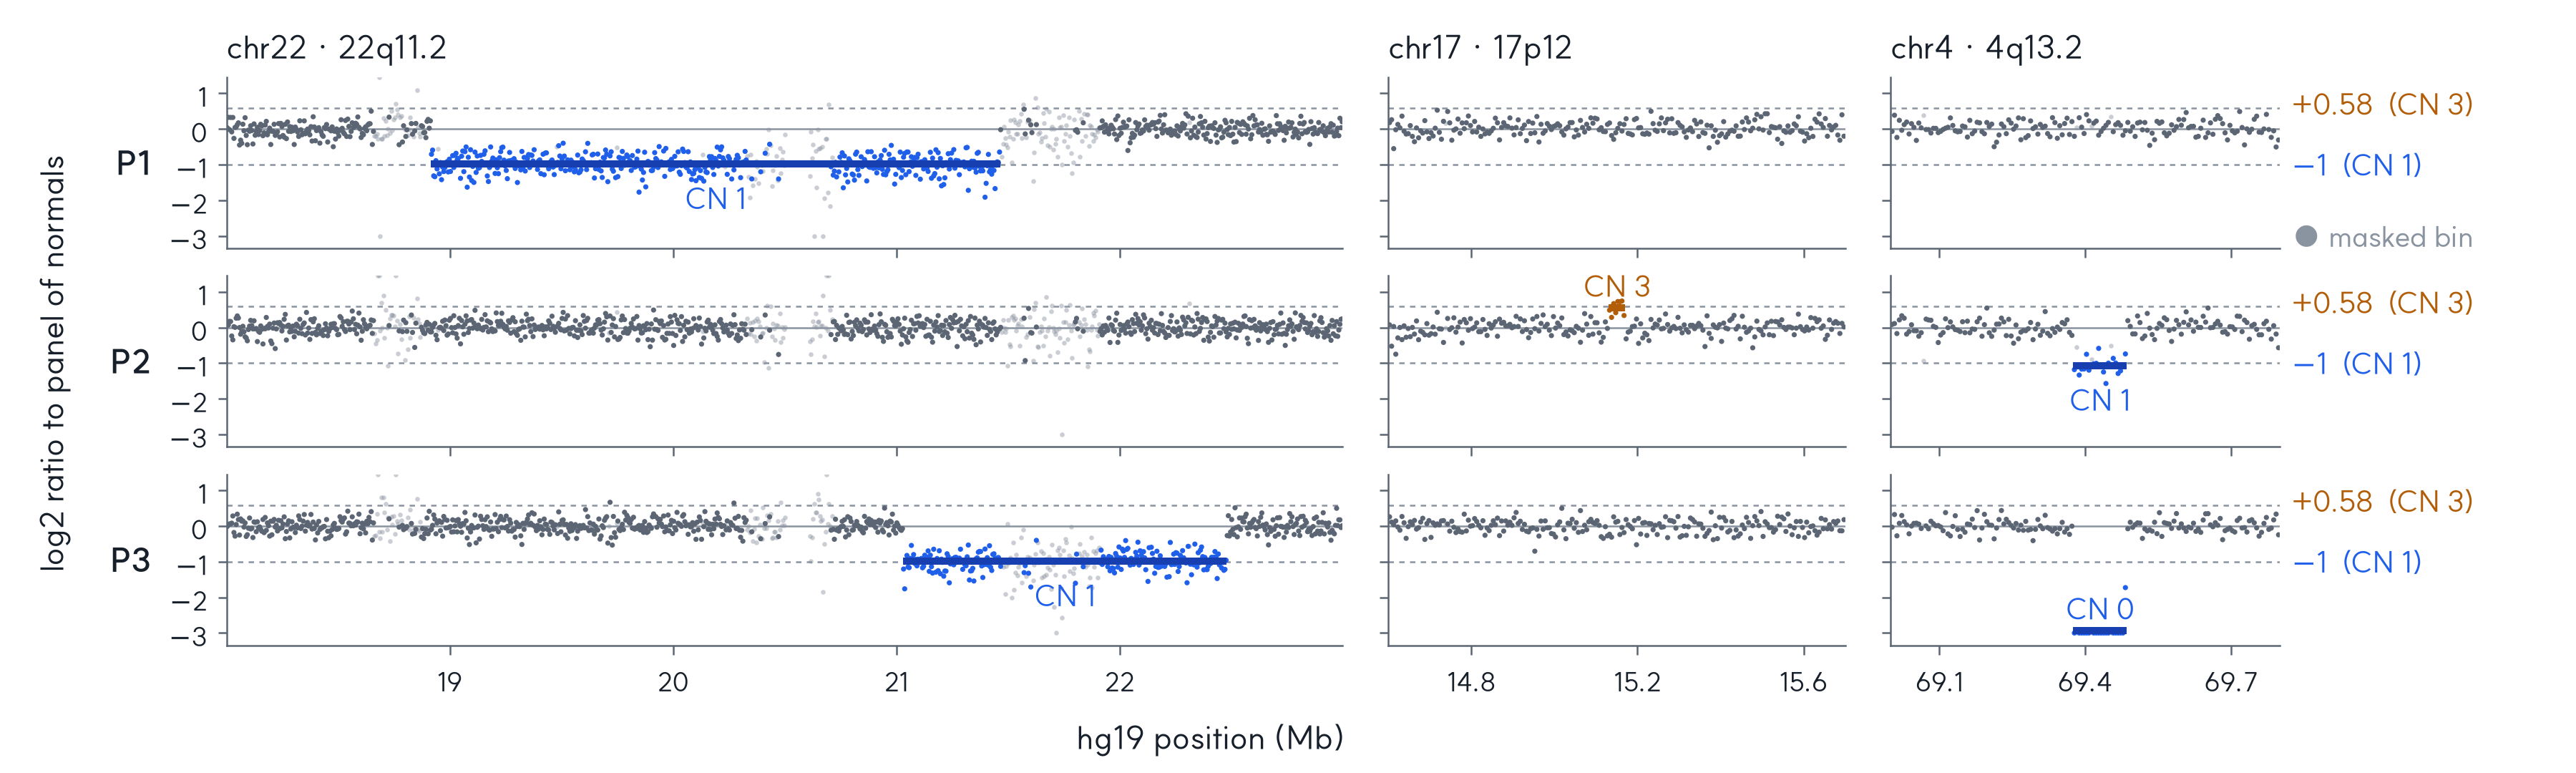

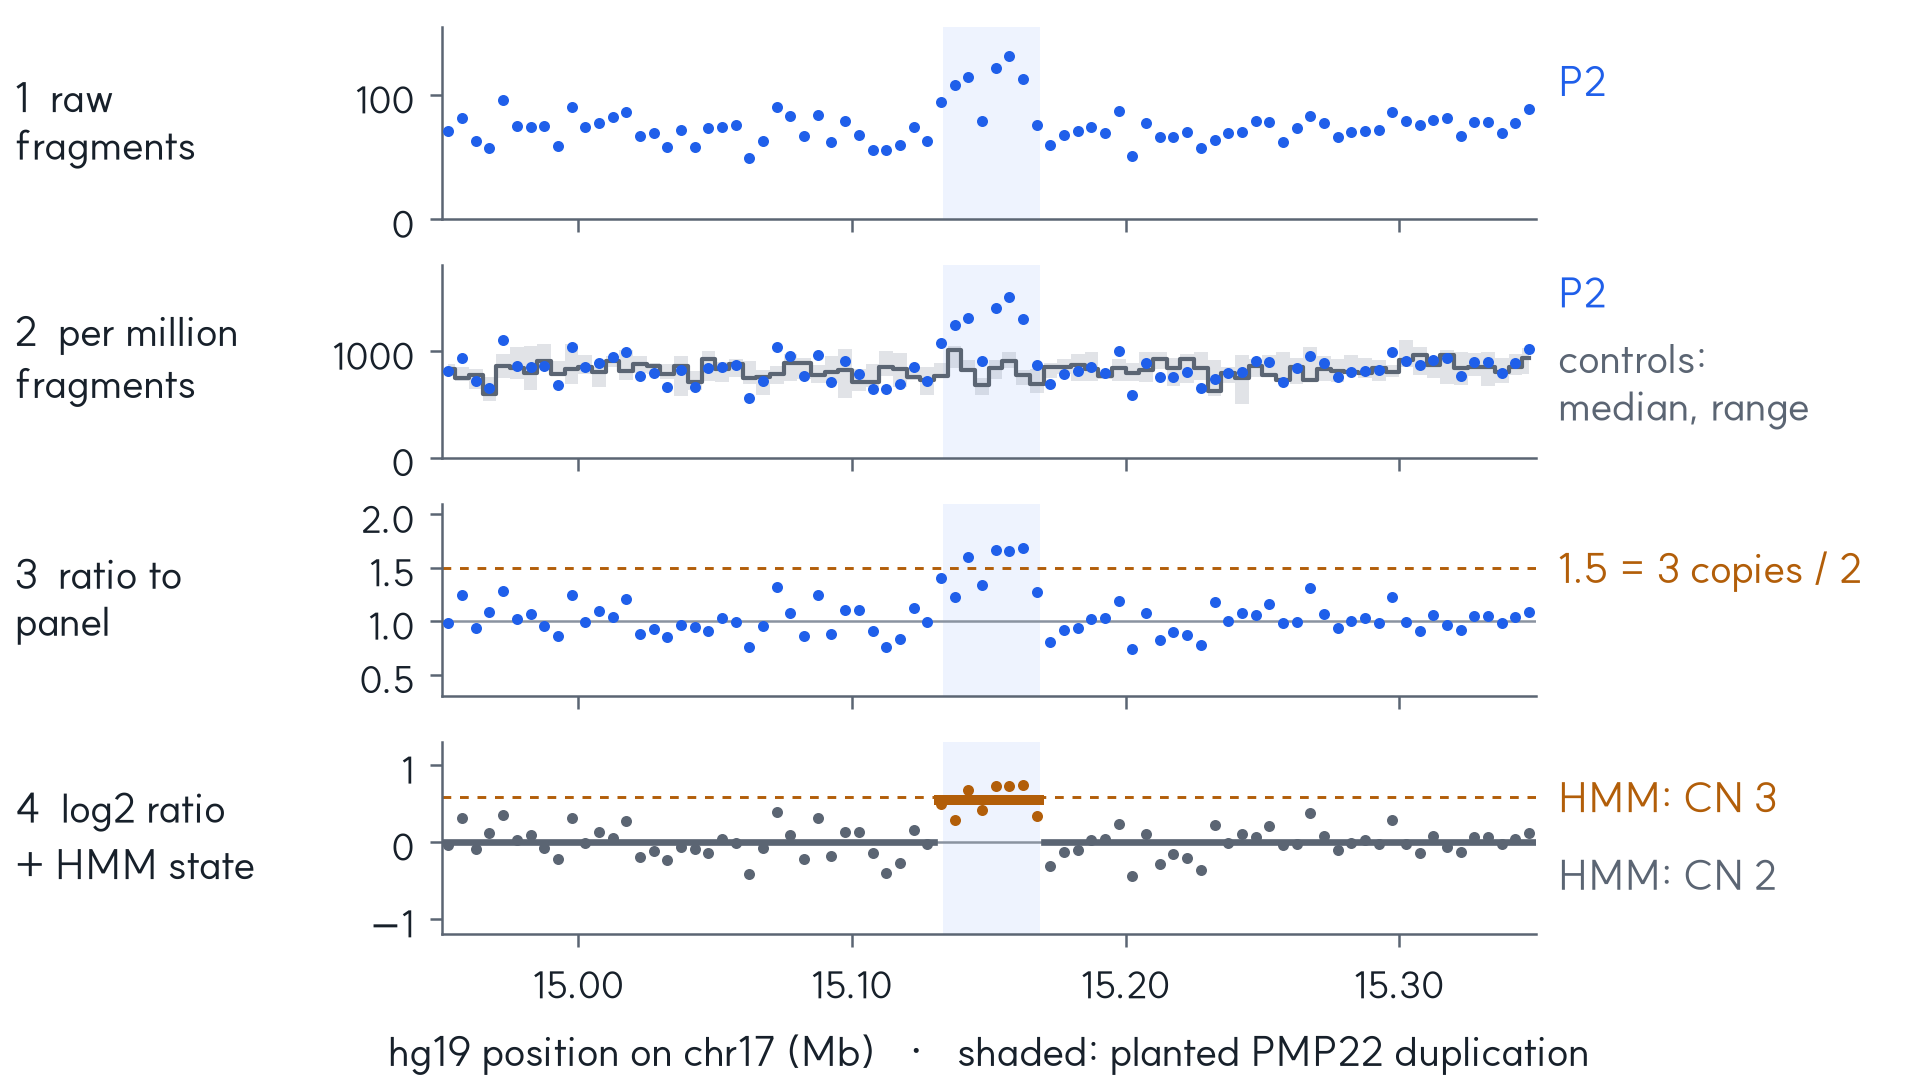

In [15]:
# Slide figures: CNV profiles (P1-P3) and the worked example around PMP22 in P2
segs_plot = patient_calls.copy()
fig = F.fig_cnv_profiles(bins, log2c, masked, segs_plot, f"{FIG}/p2_fig_cnv_profiles.png")
problems = F.layout_problems(fig); plt.close(fig)

x0, x1 = 14_950_000, 15_350_000
sel = ((bins.chrom == "chr17") & (bins.start >= x0) & (bins.end <= x1)).values
xc = ((bins.start + bins.end) / 2).values[sel]
seg = patient_calls[patient_calls.cnv_id == "P2_PMP22_DUP"].iloc[0]
t = truth[truth.cnv_id == "P2_PMP22_DUP"].iloc[0]
fig = F.fig_caller_steps(x0, x1, xc, counts.P2.values[sel], pm.P2.values[sel], panel.values[sel], ratio.P2.values[sel],
                         log2c.P2.values[sel], masked.values[sel], (seg.start, seg.end, seg.log2), (t.start0, t.end),
                         f"{FIG}/p2_fig_caller_steps.png", ctrl_pm_min=pon_pm.min(axis=1).values[sel],
                         ctrl_pm_max=pon_pm.max(axis=1).values[sel])
problems += F.layout_problems(fig); plt.close(fig)
print("layout problems:", problems)
display(Image(f"{FIG}/p2_fig_cnv_profiles.png", width=1000))
display(Image(f"{FIG}/p2_fig_caller_steps.png", width=560))

**What changed?** 1,380 noisy log2 values per sample → a short list of **segments** (`data/results/cnv_calls_hg19.bed`),
each with a copy number. All five planted events in the patients were recovered with the right copy number and there were
no false calls. Run on every control (each compared with the other four), the caller finds exactly one CNV: C2's common
UGT2B17 deletion – a true CNV in a healthy person.

The breakpoints are only as precise as the bins (±5 kb) – and for the 22q11.2 deletions the true breakpoints lie inside the
masked LCR22 repeats, so short-read depth cannot place them exactly. Real pipelines use the same ideas with more care:
**CNVkit** and **GATK gCNV** (read depth with large panels), and read-depth + split-read/discordant-pair callers such as
**Manta**, **DELLY** or **LUMPY** for base-pair breakpoints. Clinical labs confirm with arrays, MLPA or qPCR.

**Your turn.** The planted PMP22 duplication is 35.6 kb; the call is 40 kb. Where does the difference come from, and how
could you get the exact breakpoints?

<details><summary>Answer</summary>

The caller works on a 5-kb grid: the planted breakpoints fall *inside* the first and last bins, and those partly duplicated
bins were assigned to CN 3, so the call is rounded outwards to bin edges (start −3.1 kb, end +1.3 kb). Exact breakpoints
need reads that cross the junction: split reads and discordant read pairs (Manta, DELLY, LUMPY), long reads, or a targeted
assay.
</details>

## Step 4 · Liftover from hg19 to hg38 – and how to check it  *(10 min)*

### Why this step

Everything after this step (MANE genes, RNA, ClinGen/ClinVar tracks, TESSERACT-CNV) uses **hg38**. A **chain file** describes
how blocks of hg19 line up with hg38; **liftover** tools such as **CrossMap** use it to translate coordinates.

Most of the genome translates by a simple shift. **Segmental duplications** are different: the LCR22 repeats that flank the
22q11.2 deletions were **assembled differently in GRCh38**. So we compare three ways of lifting the same CNV:

* **(a) whole interval** – CrossMap lifts every aligned block separately and returns **pieces**;
* **(b) breakpoint lift** – lift only the first and the last base, and join them;
* **(c) outer span** – from the first to the last base of all pieces on the main chromosome.

Then we check **sizes**, the **.unmap** file and – most important – **gene content**: the same protein-coding genes should lie
inside the CNV in hg19 annotation (RefSeq Select) and in hg38 annotation (MANE).

In [16]:
%%bash
# (a) lift each WHOLE interval with CrossMap
CHAIN=data/ref/hg19ToHg38.over.chain.gz
CrossMap bed $CHAIN data/results/cnv_calls_hg19.bed data/results/liftover_a_pieces_hg38.bed > data/results/liftover_a.log 2>&1
echo "lines in the hg19 BED:        $(wc -l < data/results/cnv_calls_hg19.bed)"
echo "pieces written (hg38):        $(wc -l < data/results/liftover_a_pieces_hg38.bed)"
echo "records in the .unmap file:   $(wc -l < data/results/liftover_a_pieces_hg38.bed.unmap)"
echo "pieces per CNV and chromosome:"
cut -f1,4 data/results/liftover_a_pieces_hg38.bed | sort | uniq -c

lines in the hg19 BED:               5
pieces written (hg38):             217
records in the .unmap file:          0
pieces per CNV and chromosome:
   1 chr1	P3_22q11_DEL
   1 chr17	P2_PMP22_DUP
 116 chr22	P1_22q11_DEL
  96 chr22	P3_22q11_DEL
   1 chr22_KI270731v1_random	P1_22q11_DEL
   1 chr4	P2_UGT2B17_DEL
   1 chr4	P3_UGT2B17_DEL


In [17]:
# (b) write the first and the last base of each CNV as 1-bp intervals
bp = []
for _, c in patient_calls.iterrows():
    bp.append((c.chrom, c.start, c.start + 1, f"{c.cnv_id}|start"))
    bp.append((c.chrom, c.end - 1, c.end, f"{c.cnv_id}|end"))
pd.DataFrame(bp).to_csv("data/results/liftover_b_breakpoints_hg19.bed", sep="\t", header=False, index=False)
subprocess.run("CrossMap bed data/ref/hg19ToHg38.over.chain.gz data/results/liftover_b_breakpoints_hg19.bed "
               "data/results/liftover_b_breakpoints_hg38.bed > data/results/liftover_b.log 2>&1", shell=True, check=True)
print(open("data/results/liftover_b_breakpoints_hg38.bed").read())

chr22	18927487	18927488	P1_22q11_DEL|start
chr22	21110710	21110711	P1_22q11_DEL|end
chr17	15226683	15226684	P2_PMP22_DUP|start
chr17	15266682	15266683	P2_PMP22_DUP|end
chr4	68509282	68509283	P2_UGT2B17_DEL|start
chr4	68619281	68619282	P2_UGT2B17_DEL|end
chr22	20675712	20675713	P3_22q11_DEL|start
chr22	22125605	22125606	P3_22q11_DEL|end
chr4	68509282	68509283	P3_UGT2B17_DEL|start
chr4	68619281	68619282	P3_UGT2B17_DEL|end



In [18]:
# Compare (a) pieces, (b) breakpoint lift and (c) outer span; then the gene-content check
genes19 = pd.read_csv("data/annotation/genes_hg19_refseqselect_windows.tsv", sep="\t")
genes38 = pd.read_csv("data/annotation/genes_hg38_mane_select.tsv.gz", sep="\t")
sd38 = pd.read_csv("data/tracks_hg38/genomicSuperDups.tsv.gz", sep="\t")
SEGDUP38 = {c: merge_intervals(sd38.chromStart[sd38.chrom == c], sd38.chromEnd[sd38.chrom == c]) for c in sd38.chrom.unique()}

def genes_in(gdf, chrom, s0, e):
    # protein-coding genes that overlap [s0, e) by at least 1 bp
    return sorted(gdf.gene[(gdf.chrom == chrom) & (gdf.start0 < e) & (gdf.end > s0)])

def segdup_fraction(iv, s0, e):
    if iv is None or len(iv) == 0:
        return 0.0
    return float(np.clip(np.minimum(iv[:, 1], e) - np.maximum(iv[:, 0], s0), 0, None).sum() / (e - s0))

def read_lift(path_pieces, path_bp):
    pieces = pd.read_csv(path_pieces, sep="\t", header=None, usecols=[0, 1, 2, 3], names=["chrom", "start", "end", "name"])
    bpl = pd.read_csv(path_bp, sep="\t", header=None, usecols=[0, 1, 2, 3], names=["chrom", "start", "end", "name"])
    bpl[["cnv_id", "side"]] = bpl.name.str.split("|", expand=True)
    return pieces, bpl

def liftover_table(hg19_df, pieces, bpl, id_col="cnv_id"):
    rows = []
    for _, c in hg19_df.iterrows():
        p = pieces[pieces.name == c[id_col]]
        main = p[p.chrom == c.chrom]
        s = bpl[(bpl.cnv_id == c[id_col]) & (bpl.side == "start")]
        e = bpl[(bpl.cnv_id == c[id_col]) & (bpl.side == "end")]
        assert len(s) == len(e) == 1 and s.chrom.iloc[0] == e.chrom.iloc[0] == c.chrom, "breakpoint did not lift"
        b0, b1 = sorted([int(s.start.iloc[0]), int(e.start.iloc[0])])
        bp_iv = (b0, b1 + 1)
        outer = (int(main.start.min()), int(main.end.max()))
        g19 = genes_in(genes19, c.chrom, c.start, c.end)
        g38 = genes_in(genes38, c.chrom, *bp_iv)
        g38o = genes_in(genes38, c.chrom, *outer)
        rows.append({"cnv_id": c[id_col], "hg19": f"{c.chrom}:{c.start + 1:,}-{c.end:,}", "hg19 size (kb)": round((c.end - c.start) / 1e3, 1),
                     "(a) pieces": len(p), "(a) pieces off main chrom": ", ".join(f"{r.chrom}:{r.start + 1}-{r.end}" for r in p[p.chrom != c.chrom].itertuples()) or "-",
                     "(a) lifted bp (kb)": round((p.end - p.start).sum() / 1e3, 1),
                     "(b) breakpoint lift": f"{c.chrom}:{bp_iv[0] + 1:,}-{bp_iv[1]:,}", "(b) size (kb)": round((bp_iv[1] - bp_iv[0]) / 1e3, 1),
                     "(c) outer span": f"{c.chrom}:{outer[0] + 1:,}-{outer[1]:,}", "(c) size (kb)": round((outer[1] - outer[0]) / 1e3, 1),
                     "genes hg19": len(g19), "genes hg38 (b)": len(g38), "genes hg38 (c)": len(g38o),
                     "only hg19": sorted(set(g19) - set(g38)), "only hg38 (b)": sorted(set(g38) - set(g19)),
                     "extra in (c)": sorted(set(g38o) - set(g38)),
                     "_bp_iv": bp_iv, "_outer": outer, "_chrom": c.chrom, "_g19": g19, "_g38": g38})
    return pd.DataFrame(rows)

pieces_a, bp_b = read_lift("data/results/liftover_a_pieces_hg38.bed", "data/results/liftover_b_breakpoints_hg38.bed")
unmapped = open("data/results/liftover_a_pieces_hg38.bed.unmap").read().strip()
lift = liftover_table(patient_calls, pieces_a, bp_b)
show = [c for c in lift.columns if not c.startswith("_") and c not in ("only hg19", "only hg38 (b)", "extra in (c)")]
display(lift[show])
print(".unmap file:", repr(unmapped) if unmapped else "empty")
for _, r in lift.iterrows():
    if r["only hg19"] or r["only hg38 (b)"] or r["extra in (c)"]:
        print(f"{r.cnv_id}: only hg19 {r['only hg19']} | only hg38 {r['only hg38 (b)']} | extra genes in outer span {r['extra in (c)']}")

,cnv_id,hg19,hg19 size (kb),(a) pieces,(a) pieces off main chrom,(a) lifted bp (kb),(b) breakpoint lift,(b) size (kb),(c) outer span,(c) size (kb),genes hg19,genes hg38 (b),genes hg38 (c)
0,P1_22q11_DEL,"chr22:18,915,001-21,465,000",2550.0,117,chr22_KI270731v1_random:120986-121187,2449.8,"chr22:18,927,488-21,110,711",2183.2,"chr22:18,339,130-21,343,827",3004.7,48,43,48
1,P2_PMP22_DUP,"chr17:15,130,001-15,170,000",40.0,1,-,40.0,"chr17:15,226,684-15,266,683",40.0,"chr17:15,226,684-15,266,683",40.0,1,1,1
2,P2_UGT2B17_DEL,"chr4:69,375,001-69,485,000",110.0,1,-,110.0,"chr4:68,509,283-68,619,282",110.0,"chr4:68,509,283-68,619,282",110.0,1,1,1
3,P3_22q11_DEL,"chr22:21,030,001-22,480,000",1450.0,97,chr1:226114942-226114970,1449.6,"chr22:20,675,713-22,125,606",1449.9,"chr22:20,668,232-22,125,606",1457.4,24,24,24
4,P3_UGT2B17_DEL,"chr4:69,375,001-69,485,000",110.0,1,-,110.0,"chr4:68,509,283-68,619,282",110.0,"chr4:68,509,283-68,619,282",110.0,1,1,1


.unmap file: empty
P1_22q11_DEL: only hg19 ['FAM246B', 'FAM246C', 'GGTLC3', 'RIMBP3', 'TMEM191B'] | only hg38 [] | extra genes in outer span ['DGCR6', 'FAM246B', 'GGTLC3', 'RIMBP3', 'TMEM191B']


In [19]:
# Where are the genes that differ? (fraction of each gene inside segmental duplications, hg19 and hg38)
diff_rows = []
for _, r in lift.iterrows():
    for gname in r["only hg19"] + r["only hg38 (b)"] + r["extra in (c)"]:
        a = genes19[genes19.gene == gname]
        b = genes38[genes38.gene == gname]
        diff_rows.append({"cnv_id": r.cnv_id, "gene": gname,
                          "hg19 position": f"{a.chrom.iloc[0]}:{a.start0.iloc[0] + 1:,}" if len(a) else "-",
                          "hg19 in segdup": round(segdup_fraction(SEGDUP19.get(a.chrom.iloc[0]), a.start0.iloc[0], a.end.iloc[0]), 2) if len(a) else None,
                          "hg38 position": f"{b.chrom.iloc[0]}:{b.start0.iloc[0] + 1:,}" if len(b) else "no MANE transcript",
                          "hg38 in segdup": round(segdup_fraction(SEGDUP38.get(b.chrom.iloc[0]), b.start0.iloc[0], b.end.iloc[0]), 2) if len(b) else None,
                          "why it differs": "in the hg19 call but outside the hg38 breakpoint lift" if gname in r["only hg19"]
                                            else ("only in the outer span" if gname in r["extra in (c)"] else "only in hg38")})
gene_diff = pd.DataFrame(diff_rows)
display(gene_diff)

,cnv_id,gene,hg19 position,hg19 in segdup,hg38 position,hg38 in segdup,why it differs
0,P1_22q11_DEL,FAM246B,"chr22:20,483,851",1.0,"chr22:18,633,984",1.0,in the hg19 call but outside the hg38 breakpoint lift
1,P1_22q11_DEL,FAM246C,"chr22:19,017,037",1.0,no MANE transcript,NaN,in the hg19 call but outside the hg38 breakpoint lift
2,P1_22q11_DEL,GGTLC3,"chr22:20,366,211",1.0,"chr22:18,516,344",1.0,in the hg19 call but outside the hg38 breakpoint lift
3,P1_22q11_DEL,RIMBP3,"chr22:20,455,682",1.0,"chr22:18,605,815",1.0,in the hg19 call but outside the hg38 breakpoint lift
4,P1_22q11_DEL,TMEM191B,"chr22:20,377,669",1.0,"chr22:18,527,802",1.0,in the hg19 call but outside the hg38 breakpoint lift
5,P1_22q11_DEL,DGCR6,"chr22:18,893,833",1.0,"chr22:18,906,320",1.0,only in the outer span
6,P1_22q11_DEL,FAM246B,"chr22:20,483,851",1.0,"chr22:18,633,984",1.0,in the hg19 call but outside the hg38 breakpoint lift
7,P1_22q11_DEL,GGTLC3,"chr22:20,366,211",1.0,"chr22:18,516,344",1.0,in the hg19 call but outside the hg38 breakpoint lift
8,P1_22q11_DEL,RIMBP3,"chr22:20,455,682",1.0,"chr22:18,605,815",1.0,in the hg19 call but outside the hg38 breakpoint lift
9,P1_22q11_DEL,TMEM191B,"chr22:20,377,669",1.0,"chr22:18,527,802",1.0,in the hg19 call but outside the hg38 breakpoint lift


### The public record: the same 22q11.2 deletion in ClinVar

P1's deletion was planted at the coordinates of ClinVar **VCV000155158** (GRCh37 chr22:18,916,842–21,465,662). ClinVar also
lists a GRCh38 interval for it: **chr22:18,339,130–21,111,373**. Let us lift the public GRCh37 record ourselves, in the same
three ways, and compare.

In [20]:
# Lift the PUBLIC (planted) records in the same three ways and compare with the published GRCh38 coordinates
uniq_truth = truth.drop_duplicates(["chrom", "start0", "end"]).copy()
uniq_truth["rid"] = uniq_truth.cnv_id
uniq_truth[["chrom", "start0", "end", "rid"]].to_csv("data/results/planted_hg19.bed", sep="\t", header=False, index=False)
bp = []
for _, t in uniq_truth.iterrows():
    bp += [(t.chrom, t.start0, t.start0 + 1, f"{t.rid}|start"), (t.chrom, t.end - 1, t.end, f"{t.rid}|end")]
pd.DataFrame(bp).to_csv("data/results/planted_breakpoints_hg19.bed", sep="\t", header=False, index=False)
for a, b in [("planted_hg19.bed", "planted_pieces_hg38.bed"), ("planted_breakpoints_hg19.bed", "planted_breakpoints_hg38.bed")]:
    subprocess.run(f"CrossMap bed data/ref/hg19ToHg38.over.chain.gz data/results/{a} data/results/{b} > /dev/null 2>&1", shell=True, check=True)
pp, pb = read_lift("data/results/planted_pieces_hg38.bed", "data/results/planted_breakpoints_hg38.bed")
lift_public = liftover_table(uniq_truth.rename(columns={"start0": "start"}), pp, pb, id_col="rid")
PUBLIC_GRCH38 = {"P1_22q11_LCR22A-D_DEL": ("ClinVar VCV000155158", 18339129, 21111373),
                 "P2_PMP22_DUP": ("LOVD PMP22_000101", 15229776, 15265357),
                 "P2_UGT2B17_DEL": ("ClinVar VCV000147015", 68509450, 68617530)}
lift_public["public GRCh38"] = lift_public.cnv_id.map(lambda k: f"{PUBLIC_GRCH38[k][0]}: {PUBLIC_GRCH38[k][1] + 1:,}-{PUBLIC_GRCH38[k][2]:,}" if k in PUBLIC_GRCH38 else "-")
display(lift_public[["cnv_id", "hg19", "hg19 size (kb)", "(a) pieces", "(b) breakpoint lift", "(b) size (kb)",
                     "(c) outer span", "(c) size (kb)", "public GRCh38"]])

,cnv_id,hg19,hg19 size (kb),(a) pieces,(b) breakpoint lift,(b) size (kb),(c) outer span,(c) size (kb),public GRCh38
0,P1_22q11_LCR22A-D_DEL,"chr22:18,916,842-21,465,662",2548.8,117,"chr22:18,929,329-21,111,373",2182.0,"chr22:18,339,130-21,343,827",3004.7,"ClinVar VCV000155158: 18,339,130-21,111,373"
1,P2_PMP22_DUP,"chr17:15,133,094-15,168,674",35.6,1,"chr17:15,229,777-15,265,357",35.6,"chr17:15,229,777-15,265,357",35.6,"LOVD PMP22_000101: 15,229,777-15,265,357"
2,P2_UGT2B17_DEL,"chr4:69,375,169-69,483,248",108.1,1,"chr4:68,509,451-68,617,530",108.1,"chr4:68,509,451-68,617,530",108.1,"ClinVar VCV000147015: 68,509,451-68,617,530"
3,P3_22q11_distal_DEL,"chr22:21,029,655-22,481,498",1451.8,97,"chr22:20,675,367-22,127,104",1451.7,"chr22:20,668,232-22,127,104",1458.9,-


In [21]:
# CHECK · liftover facts and the gene-content rule
pub = lift_public.set_index("cnv_id")
assert pub.loc["P1_22q11_LCR22A-D_DEL", "(b) breakpoint lift"] == "chr22:18,929,329-21,111,373"
assert pub.loc["P3_22q11_distal_DEL", "(b) breakpoint lift"] == "chr22:20,675,367-22,127,104"
assert pub.loc["P2_PMP22_DUP", "(b) breakpoint lift"] == "chr17:15,229,777-15,265,357" and pub.loc["P2_PMP22_DUP", "(a) pieces"] == 1
p1 = pub.loc["P1_22q11_LCR22A-D_DEL"]
print(f"P1 public record: hg19 {p1['hg19 size (kb)'] / 1e3:.2f} Mb | breakpoint lift {p1['(b) size (kb)'] / 1e3:.2f} Mb | "
      f"outer span {p1['(c) size (kb)'] / 1e3:.2f} Mb | ClinVar GRCh38 {(21111373 - 18339129) / 1e6:.2f} Mb")
print("ClinVar GRCh38 start == first base of the most proximal CrossMap piece:",
      p1["_outer"][0] == PUBLIC_GRCH38["P1_22q11_LCR22A-D_DEL"][1],
      "| ClinVar GRCh38 end == lifted end breakpoint:", p1["_bp_iv"][1] == PUBLIC_GRCH38["P1_22q11_LCR22A-D_DEL"][2])
# gene rule: every gene that differs between builds must lie (almost) entirely in segmental duplications
lcr_only = gene_diff[gene_diff["why it differs"] != "only in the outer span"]
assert (lcr_only["hg19 in segdup"].fillna(1) >= 0.9).all(), "a unique-sequence gene changed between builds - inspect it!"
print("genes that differ between hg19 and the hg38 breakpoint lift:", len(lcr_only), "- all inside segmental duplications")

# final hg38 BED: breakpoint lift for every call
lift_ix = lift.set_index("cnv_id")
calls_hg38 = patient_calls.copy()
calls_hg38["chrom38"] = calls_hg38.cnv_id.map(lift_ix["_chrom"])
calls_hg38["start38"] = calls_hg38.cnv_id.map(lambda k: lift_ix.loc[k, "_bp_iv"][0])
calls_hg38["end38"] = calls_hg38.cnv_id.map(lambda k: lift_ix.loc[k, "_bp_iv"][1])
calls_hg38["size38"] = calls_hg38.end38 - calls_hg38.start38
calls_hg38[["chrom38", "start38", "end38", "cnv_id", "cn"]].to_csv("data/results/cnv_calls_hg38.bed", sep="\t", header=False, index=False)
print(open("data/results/cnv_calls_hg38.bed").read())

P1 public record: hg19 2.55 Mb | breakpoint lift 2.18 Mb | outer span 3.00 Mb | ClinVar GRCh38 2.77 Mb
ClinVar GRCh38 start == first base of the most proximal CrossMap piece: True | ClinVar GRCh38 end == lifted end breakpoint: True
genes that differ between hg19 and the hg38 breakpoint lift: 9 - all inside segmental duplications
chr22	18927487	21110711	P1_22q11_DEL	1
chr17	15226683	15266683	P2_PMP22_DUP	3
chr4	68509282	68619282	P2_UGT2B17_DEL	1
chr22	20675712	22125606	P3_22q11_DEL	1
chr4	68509282	68619282	P3_UGT2B17_DEL	0



layout problems: []


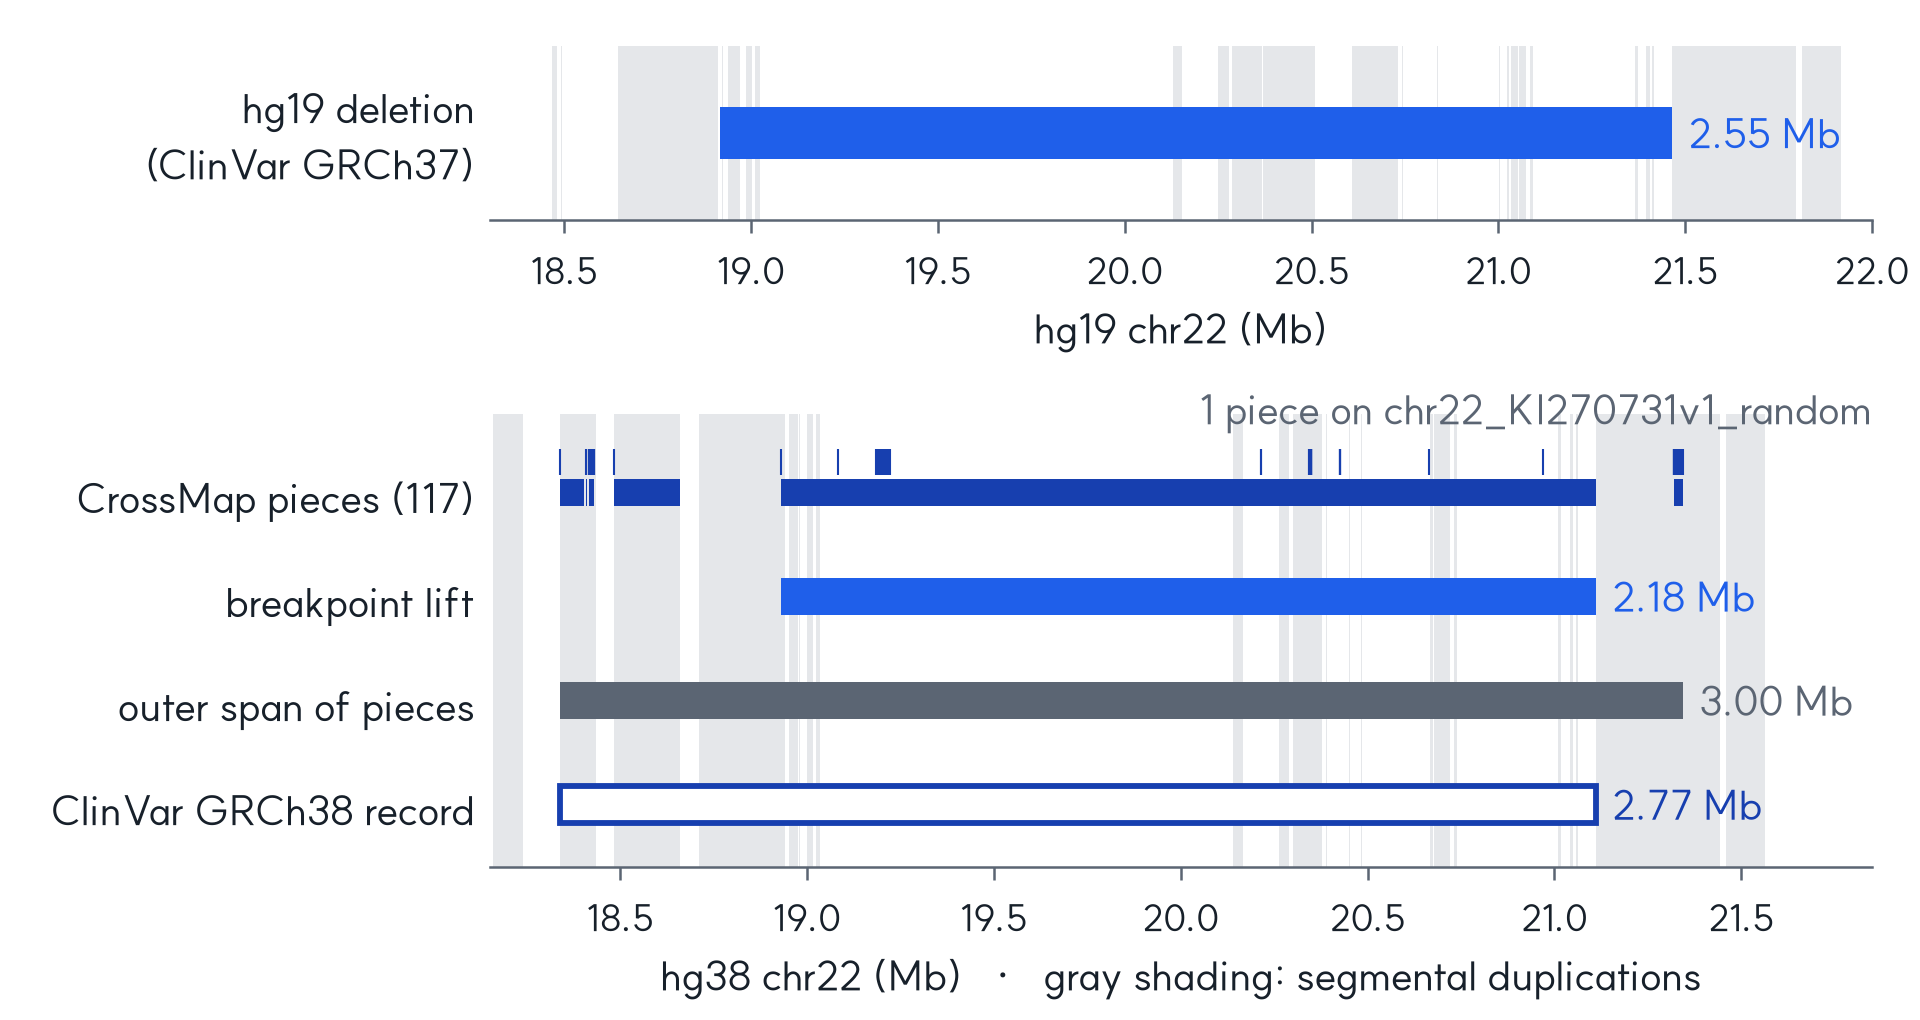

In [22]:
# Slide figure: the liftover lesson for the 22q11.2 deletion of P1 (public record = planted interval)
p1 = lift_public.set_index("cnv_id").loc["P1_22q11_LCR22A-D_DEL"]
t1 = truth[truth.cnv_id == "P1_22q11_LCR22A-D_DEL"].iloc[0]
pcs = pp[(pp.name == "P1_22q11_LCR22A-D_DEL") & (pp.chrom == "chr22")]
off = pp[(pp.name == "P1_22q11_LCR22A-D_DEL") & (pp.chrom != "chr22")]
note = " + ".join(f"1 piece on {r.chrom}" for r in off.itertuples())
xl19, xl38 = (18_300_000, 22_000_000), (18_150_000, 21_850_000)
sd19_iv = [tuple(x) for x in SEGDUP19["chr22"]]
sd38_iv = [tuple(x) for x in SEGDUP38["chr22"]]
fig = F.fig_liftover((t1.start0, t1.end), list(zip(pcs.start, pcs.end)), p1["_bp_iv"], p1["_outer"],
                     (18339129, 21111373), sd19_iv, sd38_iv, f"{FIG}/p2_fig_liftover.png", xl19, xl38,
                     off_chrom_note=note, n_pieces_total=int(p1["(a) pieces"]))
print("layout problems:", F.layout_problems(fig)); plt.close(fig)
display(Image(f"{FIG}/p2_fig_liftover.png", width=560))

**What changed?** hg19 BED → hg38 BED (`data/results/cnv_calls_hg38.bed`). For the 22q11.2 deletions, the whole-interval lift
splits into 117 (P1) and 97 (P3) pieces, including a piece on an unplaced contig (P1) and a 29-bp piece on chr1 (P3) – yet the `.unmap` file
is **empty**. Lifting the two breakpoints gives one clean interval, which is **shorter** on hg38 (P1: 2.55 Mb → 2.18 Mb)
because GRCh38 places part of the LCR22 sequence elsewhere. PMP22 and UGT2B17 lift as single pieces.

**Rule used from here on:** *breakpoint lift + gene-content check.* All unique-sequence genes (TBX1, COMT, CRKL, …) are the
same in both builds; the only differences are multi-copy genes inside LCR22 segmental duplications, where neither build can
tell us reliably whether they are deleted. The **outer span** would wrongly add DGCR6, a gene outside the deletion in hg19.

**Why does ClinVar list chr22:18,339,130–21,111,373?** NCBI's remapping reports an **outer span**: the record's GRCh38 start is
exactly the first base of the most proximal mapped piece (inside LCR22A, which is assembled differently in GRCh38), while its
end matches the lifted end breakpoint. Different tools make different choices when a region is split. Always write down
which rule you used.

**Your turn.** Why is an empty `.unmap` file **not** proof that a liftover worked?

<details><summary>Answer</summary>

CrossMap splits an interval into pieces and silently drops the parts that fall into gaps of the chain; only intervals that
cannot be placed **at all** go to `.unmap`. Compare the lifted size with the original size, look at the number of pieces and
their chromosomes, and check the gene content.
</details>

## Step 5 · Does the CNV change gene expression? Matched RNA on hg38  *(9 min)*

### Why this step

A deletion removes one copy of every gene inside it. If a gene is **expressed** in the tissue, its RNA level often drops to
about **half** (log2 fold change ≈ −1); a duplication raises it to about **1.5×** (≈ +0.58); with **CN 0** there is no RNA at
all. Seeing this "**dosage effect**" tells us that the DNA call is real and has a functional consequence. Two warnings:

* **Buffering** – some genes are regulated back towards normal levels (log2FC closer to 0).
* **Tissue** – a gene that is not expressed in the sampled tissue cannot show anything. **Absence of signal is uninformative.**

The RNA data here are **synthetic**: a "fibroblast-like" baseline (not GTEx), counts for all hg38 MANE genes in all 8 samples.

New terms: **count matrix** (genes × samples, number of RNA reads per gene); **CPM** (counts per million: corrects for
library size); **log2 fold change** (patient vs mean of the 5 controls, on log2 CPM); **z-score** (how many control standard
deviations away); **expressed** (control mean CPM ≥ 1).

In [23]:
# Step 5 · CPM, log2 fold change and z-score for every gene; genes inside each hg38 CNV
rna = pd.read_csv("data/rna/counts_hg38_mane.tsv.gz", sep="\t")
ALL = ["P1", "P2", "P3"] + CONTROLS
cpm = rna[ALL] / rna[ALL].sum() * 1e6
logc = np.log2(cpm + 0.5)
ctrl_mean, ctrl_sd = logc[CONTROLS].mean(axis=1), logc[CONTROLS].std(axis=1, ddof=1)
expressed = cpm[CONTROLS].mean(axis=1) >= 1
lfc = pd.DataFrame({s: logc[s] - ctrl_mean for s in ["P1", "P2", "P3"]})
zsc = pd.DataFrame({s: (logc[s] - ctrl_mean) / ctrl_sd for s in ["P1", "P2", "P3"]})
print(f"{len(rna):,} genes x {len(ALL)} samples; library sizes {int(rna[ALL].sum().min()):,}-{int(rna[ALL].sum().max()):,} reads;"
      f" expressed (control CPM >= 1): {expressed.mean():.0%}")

def cnv_gene_table(cnv):
    sel = (rna.chrom == cnv.chrom38) & (rna.start0 < cnv.end38) & (rna.end > cnv.start38)
    exp = np.log2(cnv.cn / 2) if cnv.cn > 0 else -np.inf
    d = pd.DataFrame({"gene": rna.gene[sel], "expressed": expressed[sel], "control CPM": cpm.loc[sel, CONTROLS].mean(axis=1).round(1),
                      "patient CPM": cpm.loc[sel, cnv["sample"]].round(1), "log2FC": lfc.loc[sel, cnv["sample"]].round(2),
                      "z": zsc.loc[sel, cnv["sample"]].round(1)})
    d["expected log2FC"] = "−∞ (no RNA)" if cnv.cn == 0 else round(exp, 2)
    d["reading"] = np.where(~d.expressed, "not expressed: uninformative",
                     np.where(cnv.cn == 0, np.where(d["patient CPM"] < 0.5, "no RNA, as expected", "RNA present!"),
                     np.where((d.log2FC - exp).abs() <= 0.5, "fits the copy number", "weaker/other (buffered? noise?)")))
    return d.reset_index(drop=True)

gene_tables = {c.cnv_id: cnv_gene_table(c) for _, c in calls_hg38.iterrows()}
rna_summary = []
for cid, d in gene_tables.items():
    e = d[d.expressed]
    rna_summary.append({"cnv_id": cid, "genes": len(d), "expressed": len(e),
                        "median log2FC (expressed)": round(float(e.log2FC.median()), 2) if len(e) else None,
                        "fits copy number": int((e.reading.isin(["fits the copy number", "no RNA, as expected"])).sum())})
rna_summary = pd.DataFrame(rna_summary)
display(rna_summary)
KEY_GENES = ["TBX1", "COMT", "CRKL", "HIRA", "PMP22", "UGT2B17"]
display(pd.concat([d[d.gene.isin(KEY_GENES)].assign(cnv_id=cid) for cid, d in gene_tables.items()]).set_index(["cnv_id", "gene"]))

19,229 genes x 8 samples; library sizes 18,817,949-30,779,501 reads; expressed (control CPM >= 1): 69%


,cnv_id,genes,expressed,median log2FC (expressed),fits copy number
0,P1_22q11_DEL,43,32,-0.85,26
1,P2_PMP22_DUP,1,1,0.55,1
2,P2_UGT2B17_DEL,1,1,-0.37,0
3,P3_22q11_DEL,24,19,-0.80,14
4,P3_UGT2B17_DEL,1,1,-3.75,1


expressed  ...                          reading
cnv_id         gene                ...                                 
P1_22q11_DEL   HIRA          True  ...  weaker/other (buffered? noise?)
               TBX1          True  ...             fits the copy number
               COMT          True  ...             fits the copy number
               CRKL          True  ...             fits the copy number
P2_PMP22_DUP   PMP22         True  ...             fits the copy number
P2_UGT2B17_DEL UGT2B17       True  ...  weaker/other (buffered? noise?)
P3_22q11_DEL   CRKL          True  ...             fits the copy number
P3_UGT2B17_DEL UGT2B17       True  ...              no RNA, as expected

[8 rows x 7 columns]

In [24]:
# UGT2B17: RNA follows DNA copy number in every sample (P3: CN 0; P2 and control C2: CN 1)
dna_cn = {"P1": 2, "P2": 1, "P3": 0, "C1": 2, "C2": 1, "C3": 2, "C4": 2, "C5": 2}
u = rna.gene == "UGT2B17"
ugt = pd.DataFrame({"DNA copy number": dna_cn, "UGT2B17 reads": rna.loc[u, ALL].iloc[0], "CPM": cpm.loc[u, ALL].iloc[0].round(2)})
print(ugt.T.to_string())

                     P1      P2   P3      C1     C2      C3      C4      C5
DNA copy number    2.00    1.00  0.0    2.00   1.00    2.00    2.00    2.00
UGT2B17 reads    179.00  135.00  0.0  184.00  76.00  144.00  252.00  125.00
CPM                7.06    4.71  0.0    6.99   3.52    6.93    8.19    6.64


In [25]:
# CHECK · dosage is visible where genes are expressed
s = rna_summary.set_index("cnv_id")
assert -1.2 < s.loc["P1_22q11_DEL", "median log2FC (expressed)"] < -0.5
assert -1.2 < s.loc["P3_22q11_DEL", "median log2FC (expressed)"] < -0.5
assert gene_tables["P2_PMP22_DUP"].set_index("gene").loc["PMP22", "log2FC"] > 0.3
assert rna.loc[u, "P3"].iloc[0] == 0
not_expr = {cid: int((~d.expressed).sum()) for cid, d in gene_tables.items()}
print("genes inside each CNV that are NOT expressed (no information about dosage):", not_expr)

genes inside each CNV that are NOT expressed (no information about dosage): {'P1_22q11_DEL': 11, 'P2_PMP22_DUP': 0, 'P2_UGT2B17_DEL': 0, 'P3_22q11_DEL': 5, 'P3_UGT2B17_DEL': 0}


### Pitfall: using hg19 coordinates on hg38 genes

What happens if someone forgets the liftover and intersects the **hg19** CNV coordinates directly with the **hg38** gene table?

,cnv_id,correct (lifted),wrong build,shared,missed,wrongly added
0,P1_22q11_DEL,43,46,43,[],"[FAM246A, HIC2, RIMBP3B]"
1,P2_PMP22_DUP,1,0,0,[PMP22],[]
2,P2_UGT2B17_DEL,1,1,0,[UGT2B17],[UGT2B4]
3,P3_22q11_DEL,24,17,16,"[AIFM3, CRKL, LZTR1, P2RX6, PI4KA, SERPIND1, SNAP29, THAP7]",[VPREB1]
4,P3_UGT2B17_DEL,1,1,0,[UGT2B17],[UGT2B4]


layout problems: []


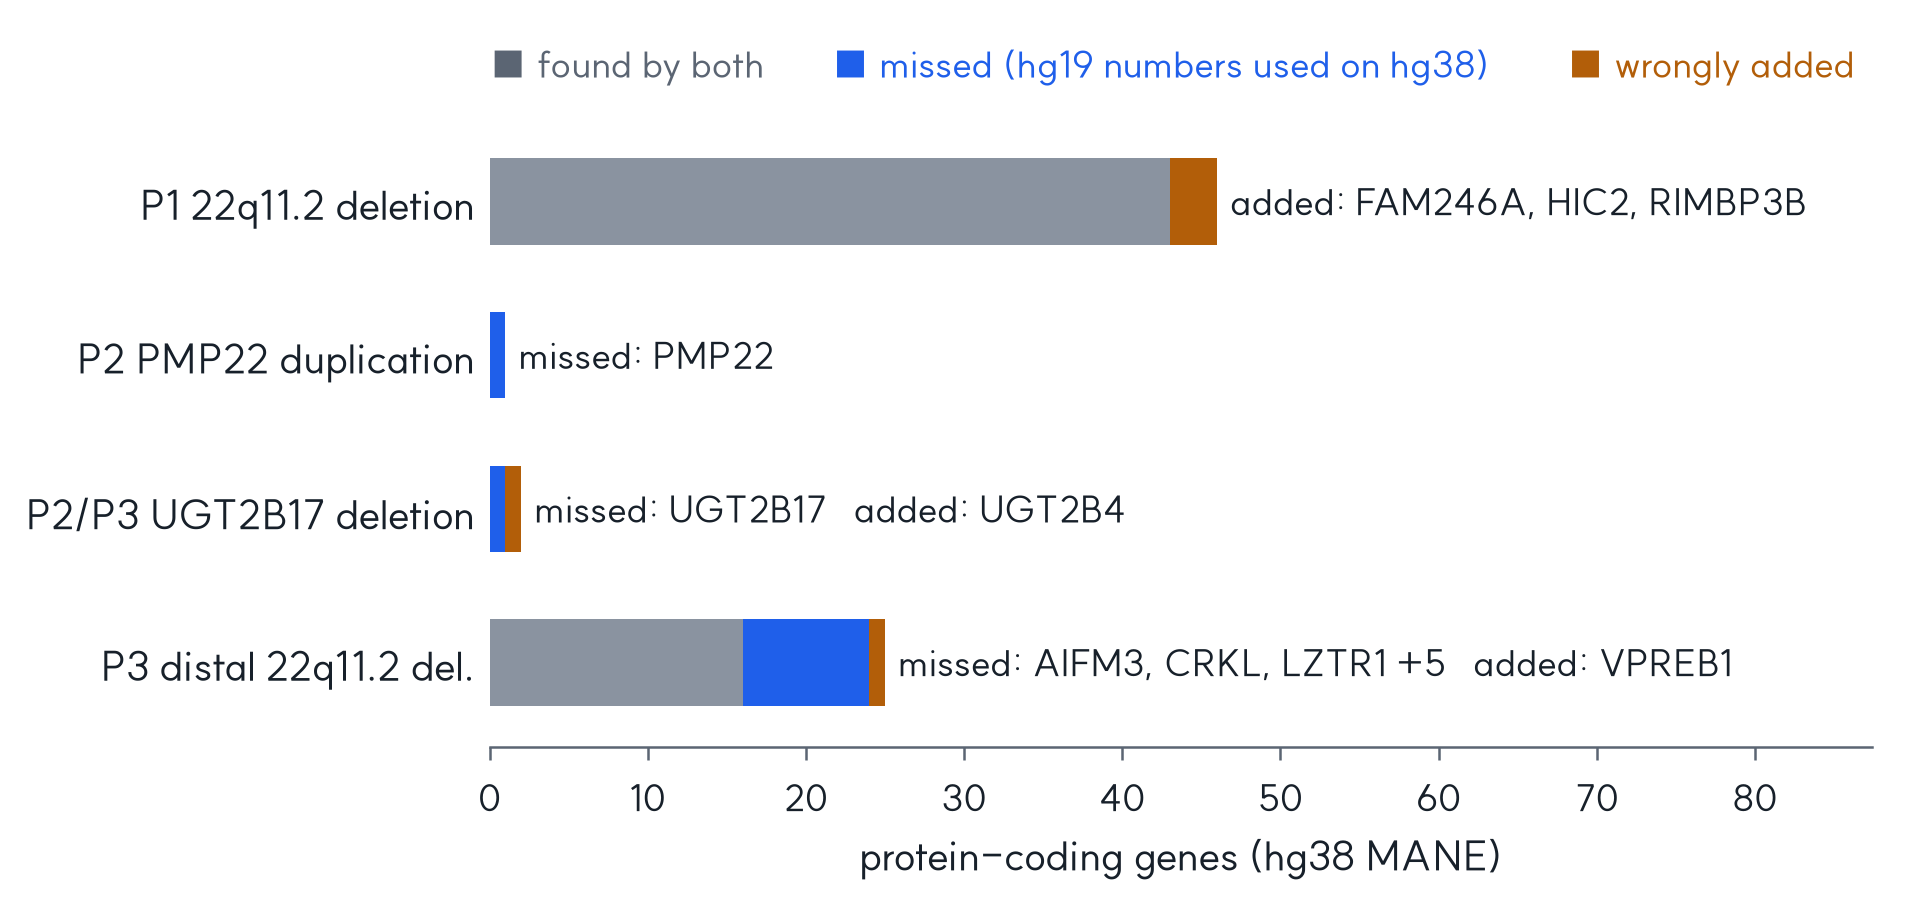

In [26]:
# The wrong-build demo: hg19 coordinates intersected with hg38 MANE genes vs the correct (lifted) intervals
wrong_rows = []
for _, c in calls_hg38.iterrows():
    wrong = genes_in(genes38, c.chrom, c.start, c.end)            # hg19 numbers used as if they were hg38
    right = genes_in(genes38, c.chrom38, c.start38, c.end38)
    wrong_rows.append({"cnv_id": c.cnv_id, "correct (lifted)": len(right), "wrong build": len(wrong),
                       "shared": len(set(wrong) & set(right)), "missed": sorted(set(right) - set(wrong)),
                       "wrongly added": sorted(set(wrong) - set(right))})
wrong_build = pd.DataFrame(wrong_rows)
display(wrong_build)
assert "PMP22" in wrong_build.set_index("cnv_id").loc["P2_PMP22_DUP", "missed"]

labels = {"P1_22q11_DEL": "P1 22q11.2 deletion", "P3_22q11_DEL": "P3 distal 22q11.2 del.",
          "P2_PMP22_DUP": "P2 PMP22 duplication", "P2_UGT2B17_DEL": "P2/P3 UGT2B17 deletion"}
fig_rows = [{"label": labels[r.cnv_id], "shared": r.shared, "missed": r.missed, "spurious": r["wrongly added"]}
            for _, r in wrong_build.iterrows() if r.cnv_id in labels]
fig = F.fig_wrong_build(fig_rows, f"{FIG}/p2_fig_wrong_build.png")
print("layout problems:", F.layout_problems(fig)); plt.close(fig)
display(Image(f"{FIG}/p2_fig_wrong_build.png", width=560))

layout problems: []


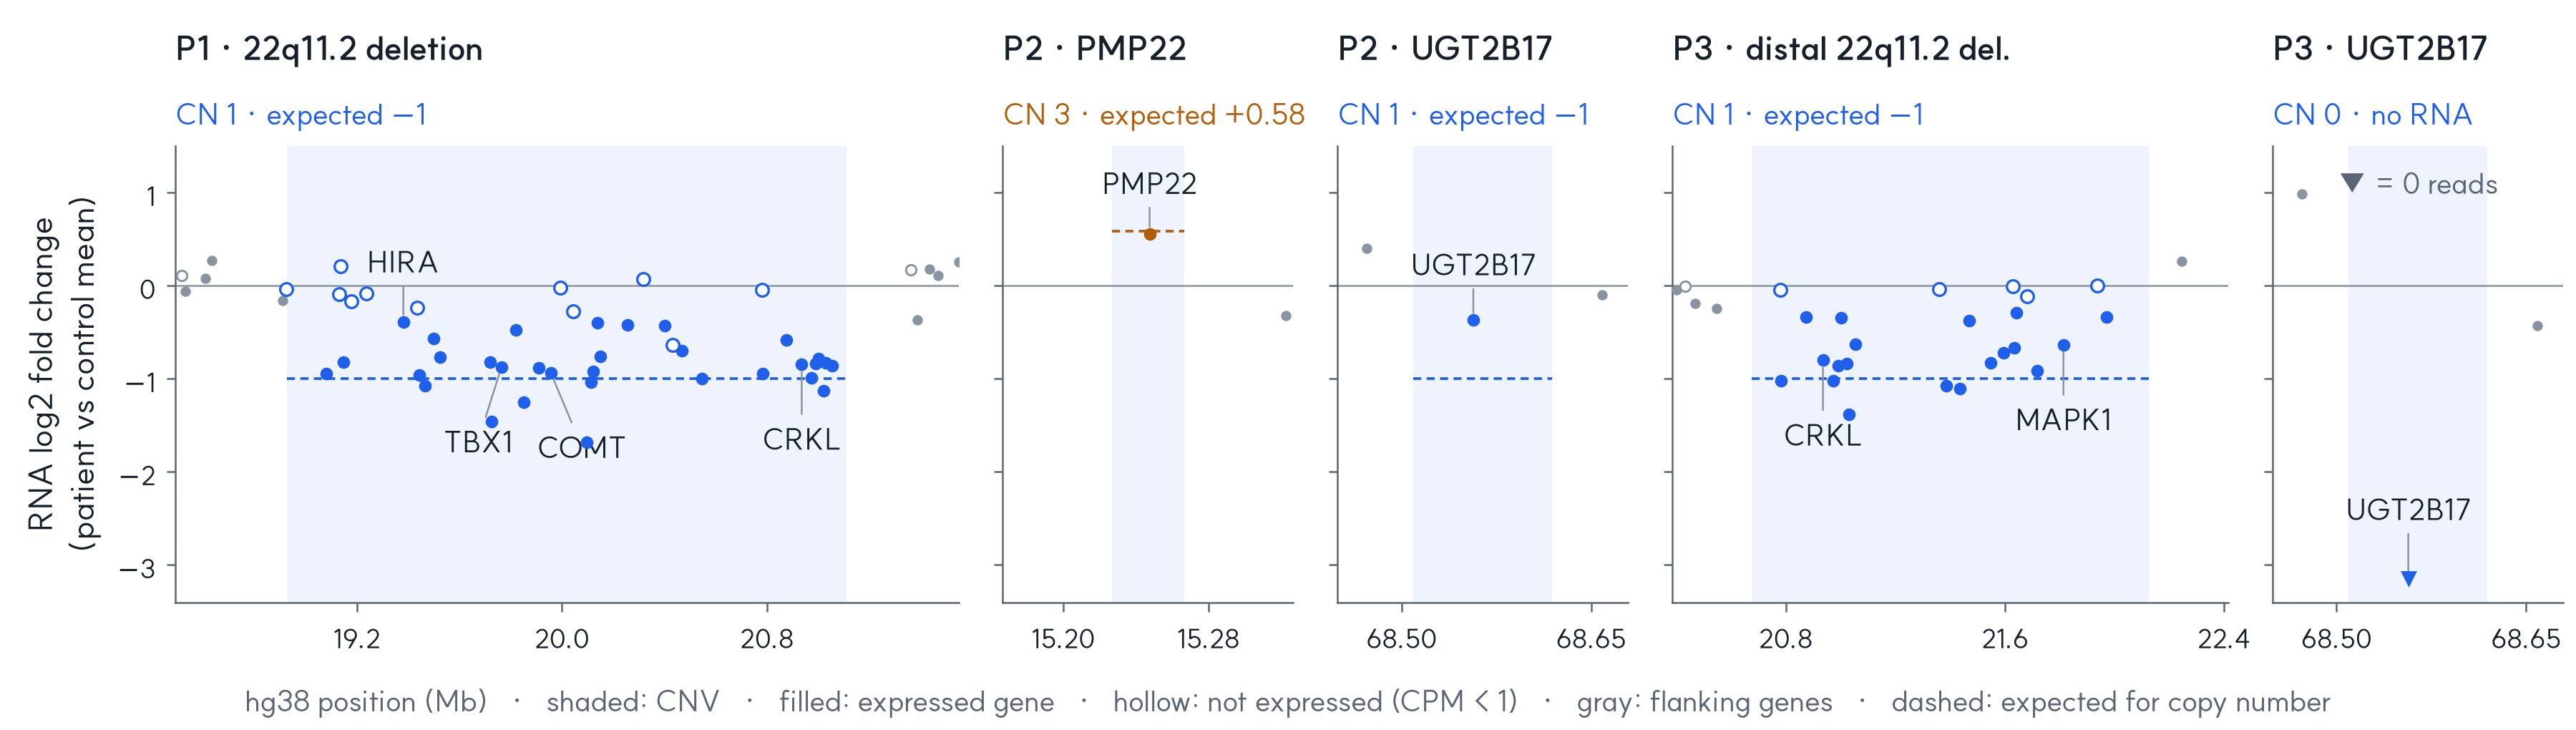

In [27]:
# Slide figure: RNA dosage along hg38 for every CNV of each patient (CNV shaded, flanking genes in gray)
def dosage_panel(cid, title, subtitle, width, label_genes, nticks=3, decimals=1, flank_min=60_000, label_dy=None,
                 label_dx=None, note=None):
    c = calls_hg38.set_index("cnv_id").loc[cid]
    fl = max(int(0.2 * c.size38), flank_min)
    x0, x1 = c.start38 - fl, c.end38 + fl
    sel = (rna.chrom == c.chrom38) & (rna.start0 < x1) & (rna.end > x0)
    g = pd.DataFrame({"gene": rna.gene[sel], "start0": rna.start0[sel], "end": rna.end[sel],
                      "log2fc": lfc.loc[sel, c["sample"]], "expressed": expressed[sel]})
    g["inside"] = (g.start0 < c.end38) & (g.end > c.start38)
    return dict(title=title, subtitle=subtitle, genes=g, cnv_start=c.start38, cnv_end=c.end38, cn=int(c.cn),
                xlim=(x0, x1), width=width, label_genes=label_genes, nticks=nticks, decimals=decimals,
                label_dy=label_dy or {}, label_dx=label_dx or {}, note=note)

panels = [dosage_panel("P1_22q11_DEL", "P1 · 22q11.2 deletion", "CN 1 · expected −1", 3.1, ["TBX1", "COMT", "CRKL", "HIRA"],
                       nticks=4, label_dy={"TBX1": -0.8, "COMT": -0.8, "CRKL": -0.8, "HIRA": 0.65},
                       label_dx={"TBX1": -0.03, "COMT": 0.04}),
          dosage_panel("P2_PMP22_DUP", "P2 · PMP22", "CN 3 · expected +0.58", 1.15, ["PMP22"], nticks=2, decimals=2,
                       label_dy={"PMP22": 0.55}),
          dosage_panel("P2_UGT2B17_DEL", "P2 · UGT2B17", "CN 1 · expected −1", 1.15, ["UGT2B17"], nticks=2, decimals=2,
                       label_dy={"UGT2B17": 0.6}),
          dosage_panel("P3_22q11_DEL", "P3 · distal 22q11.2 del.", "CN 1 · expected −1", 2.2, ["CRKL", "MAPK1"],
                       nticks=3, label_dy={"CRKL": -0.8, "MAPK1": -0.8}),
          dosage_panel("P3_UGT2B17_DEL", "P3 · UGT2B17", "CN 0 · no RNA", 1.15, ["UGT2B17"], nticks=2, decimals=2,
                       label_dy={"UGT2B17": 0.75}, note="▼ = 0 reads")]
fig = F.fig_rna_dosage(panels, f"{FIG}/p2_fig_rna_dosage.png")
print("layout problems:", F.layout_problems(fig)); plt.close(fig)
display(Image(f"{FIG}/p2_fig_rna_dosage.png", width=1000))

**What changed?** hg38 CNV intervals + RNA counts → one gene table per CNV (expressed?, log2FC, z, expected). Expressed genes
inside the 22q11.2 deletions drop by about half; PMP22 rises by about 1.5×; UGT2B17 RNA follows DNA copy number (0, 1 or 2
copies) – including control C2. P2's UGT2B17 change looks weaker than expected, partly because the control mean includes
C2, who also has only one copy. Non-expressed genes tell us nothing. (z-scores from five controls are unstable: read the
log2 fold change first.)

The wrong-build intersection **misses PMP22 completely**, swaps UGT2B17 for UGT2B4, and drops CRKL and seven other genes
from P3's deletion. Dosage effects can also be **buffered** (HIRA in P1 is only about −0.4) or **tissue-specific**
(TBX1's important role is in the embryonic pharyngeal arches, not in adult fibroblasts).

**Your turn.** HIRA lies inside P1's deletion, is expressed, but changes much less than −1. Give two possible reasons.

<details><summary>Answer</summary>

(1) **Dosage compensation/buffering**: feedback regulation raises transcription from the remaining copy. (2) **Measurement
noise**: one patient against five controls; one gene's log2FC has an uncertainty of about ±0.2–0.3. Other reasons: the
remaining allele is more active (allele-specific expression), or the gene is regulated differently in this tissue. This is
why we look at the median of all expressed genes in a CNV, not at one gene.
</details>

## Step 6 · Prepare TESSERACT-CNV input (hg38)  *(6 min)*

### What TESSERACT-CNV does

TESSERACT-CNV (Buralkin, Botas, Chang, Deng, Papastathopoulos-Katsaros, Liu & Park, *bioRxiv* 2026,
doi:10.64898/2026.05.21.726953) is a **vision-based model** for CNV pathogenicity:

* each CNV is drawn as a **base-pair-resolution, multi-track image**: **78 input channels** in **14 groups** (gene structure,
  constraint, dosage sensitivity, conservation, epigenome, regulatory elements, known pathogenic variants … plus 2
  variant-identity channels), built from GENCODE v48 on **hg38**;
* the image is cut into **500-bp windows** → a 2D CNN encodes each window → an optional sequence model (Transformer or
  Mamba-2) → an **attention-based multiple-instance-learning (MIL)** aggregator → **one score**;
* trained on the PhenoSV CNV data set (ClinVar-derived coding + matched non-coding CNVs; 19,477 CNVs: 9,229 benign,
  10,248 pathogenic; chromosome-level split); validated on held-out ClinVar and the independent DECIPHER cohort;
* designed for CNVs of **50 bp – 1 Mbp**. For longer CNVs the preprint describes **segmented inference**: the window
  sequence is split into segments of **S = 120 windows (= 60 kb)**, each scored independently, and the CNV score is the
  **maximum** over segments (top-k mean is an alternative);
* per-segment signal correlates most with dosage-sensitivity and disease-gene annotations (ClinGen gene–disease validity
  strongest), then conservation. **gnomAD SV allele frequency was deliberately excluded** as an input (label-leakage risk).

TESSERACT code and weights are **not public**. This notebook therefore prepares the input and calls the lab's installation
through **one adapter cell**. If it is not configured, the notebook says so and continues. **No score is invented anywhere.**

In [28]:
# Step 6 · the TESSERACT-CNV input table (hg38, 0-based starts) and the size check
tess_in = pd.DataFrame({"chrom": calls_hg38.chrom38, "start0": calls_hg38.start38, "end": calls_hg38.end38,
                        "cnv_type": calls_hg38["type"], "cnv_id": calls_hg38.cnv_id, "sample": calls_hg38["sample"],
                        "size_bp": calls_hg38.size38})
tess_in.to_csv("data/results/tesseract_input_hg38.tsv", sep="\t", index=False)

WINDOW, SEG_WINDOWS = 500, 120                       # 500-bp windows, 120 windows (60 kb) per segment
size_check = tess_in[["cnv_id", "cnv_type", "size_bp"]].copy()
size_check["in design range (50 bp-1 Mbp)"] = size_check.size_bp.between(50, 1_000_000)
size_check["windows (500 bp)"] = np.ceil(size_check.size_bp / WINDOW).astype(int)
size_check["segments (60 kb)"] = np.ceil(size_check["windows (500 bp)"] / SEG_WINDOWS).astype(int)
size_check["inference"] = np.where(size_check["in design range (50 bp-1 Mbp)"], "standard", "segmented (score = max over segments)")
display(size_check)

seg_rows = []
for _, r in tess_in.iterrows():
    n_win = int(np.ceil(r.size_bp / WINDOW))
    for k in range(int(np.ceil(n_win / SEG_WINDOWS))):
        a = r.start0 + k * SEG_WINDOWS * WINDOW
        b = min(r.end, a + SEG_WINDOWS * WINDOW)
        seg_rows.append({"cnv_id": r.cnv_id, "seg_index": k + 1, "chrom": r.chrom, "seg_start": a, "seg_end": b,
                         "n_windows": int(np.ceil((b - a) / WINDOW)), "seg_score": ""})
seg_grid = pd.DataFrame(seg_rows)
seg_grid.to_csv("data/results/tesseract_segments_template_hg38.tsv", sep="\t", index=False)
print(seg_grid.groupby("cnv_id").size().rename("segments in the template").to_string())

,cnv_id,cnv_type,size_bp,in design range (50 bp-1 Mbp),windows (500 bp),segments (60 kb),inference
0,P1_22q11_DEL,DEL,2183224,False,4367,37,segmented (score = max over segments)
1,P2_PMP22_DUP,DUP,40000,True,80,1,standard
2,P2_UGT2B17_DEL,DEL,110000,True,220,2,standard
3,P3_22q11_DEL,DEL,1449894,False,2900,25,segmented (score = max over segments)
4,P3_UGT2B17_DEL,DEL,110000,True,220,2,standard


cnv_id
P1_22q11_DEL      37
P2_PMP22_DUP       1
P2_UGT2B17_DEL     2
P3_22q11_DEL      25
P3_UGT2B17_DEL     2


In [29]:
# ======================= TESSERACT-CNV ADAPTER  (the ONLY cell you edit to run the model) =======================
# Set TESSERACT_CMD to the command of your lab's installation. {input} and {output} are filled in for you.
# Example (ask your instructor for the real command):
#   TESSERACT_CMD = "tesseract-cnv predict --genome hg38 --input {input} --output {output}"
TESSERACT_CMD = None
TESSERACT_INPUT = "data/results/tesseract_input_hg38.tsv"
TESSERACT_OUTPUT = "data/results/tesseract_scores.tsv"                     # expected: cnv_id, score
TESSERACT_SEGMENT_OUTPUT = "data/results/tesseract_scores.segments.tsv"    # optional: cnv_id, seg_start, seg_end, seg_score

def parse_tesseract_output(path=TESSERACT_OUTPUT, seg_path=TESSERACT_SEGMENT_OUTPUT):
    scores = pd.read_csv(path, sep="\t")
    assert {"cnv_id", "score"} <= set(scores.columns), "expected columns: cnv_id, score"
    segs = None
    if seg_path and os.path.exists(seg_path):
        segs = pd.read_csv(seg_path, sep="\t")
        assert {"cnv_id", "seg_start", "seg_end", "seg_score"} <= set(segs.columns)
    return scores, segs

tess_scores, tess_segments = None, None
if TESSERACT_CMD is None:
    print("TESSERACT-CNV not run: TESSERACT_CMD is not configured. The input is ready in", TESSERACT_INPUT,
          "and the segment template in data/results/tesseract_segments_template_hg38.tsv. Continuing without scores.")
else:
    cmd = TESSERACT_CMD.format(input=TESSERACT_INPUT, output=TESSERACT_OUTPUT)
    print("running:", cmd)
    subprocess.run(cmd, shell=True, check=True)
    tess_scores, tess_segments = parse_tesseract_output()
    display(tess_scores)

TESSERACT-CNV not run: TESSERACT_CMD is not configured. The input is ready in data/results/tesseract_input_hg38.tsv and the segment template in data/results/tesseract_segments_template_hg38.tsv. Continuing without scores.


In [30]:
# Parse + plot ONLY if real TESSERACT output exists
if tess_scores is not None and tess_segments is not None:
    fig, ax = plt.subplots(figsize=(6.4, 2.4))
    for cid, d in tess_segments.groupby("cnv_id"):
        ax.plot((d.seg_start + d.seg_end) / 2 / 1e6, d.seg_score, marker="o", lw=1, label=cid)
    ax.set_xlabel("hg38 position (Mb)"); ax.set_ylabel("segment score"); ax.legend(fontsize=8)
    fig.savefig(f"{NBFIG}/step6_tesseract_segments.png", dpi=150); plt.close(fig)
    display(Image(f"{NBFIG}/step6_tesseract_segments.png"))
else:
    print("No TESSERACT output to plot (model not run). Nothing is simulated or filled in.")

No TESSERACT output to plot (model not run). Nothing is simulated or filled in.


In [31]:
# CHECK · input rows, size flags and segment counts
assert len(tess_in) == len(calls_hg38) and set(tess_in.cnv_type) <= {"DEL", "DUP"}
assert (tess_in.end > tess_in.start0).all()
flagged = size_check[~size_check["in design range (50 bp-1 Mbp)"]].cnv_id.tolist()
print("outside the 50 bp-1 Mbp design range -> segmented inference:", flagged)
assert set(flagged) == {"P1_22q11_DEL", "P3_22q11_DEL"}
assert (seg_grid.seg_score == "").all(), "the template must stay empty unless the model was really run"
print("segment template rows:", len(seg_grid))

outside the 50 bp-1 Mbp design range -> segmented inference: ['P1_22q11_DEL', 'P3_22q11_DEL']
segment template rows: 67


**What changed?** hg38 BED → a model-ready table (`tesseract_input_hg38.tsv`), a size check and an empty 60-kb segment
template. Both 22q11.2 deletions are larger than 1 Mbp, so TESSERACT would score them in segments and report the maximum.

**Your turn.** Look at the size table. How many 500-bp windows and 60-kb segments does P1's deletion need on hg38, and why
does segmented inference report the **maximum** segment score?

<details><summary>Answer</summary>

About 4,370 windows and 37 segments (size ÷ 500, then ÷ 120, rounded up; see the table). The maximum is used because one
strongly dosage-sensitive part (for example the TBX1/CRKL region) is enough to make a deletion pathogenic: a CNV is as
dangerous as its most dangerous segment. The top-k mean is a softer alternative.
</details>

## Step 7 · Read the tracks around each CNV (hg38)  *(9 min)*

### Why this step

A model score is only useful if you understand what could drive it. The tracks below are the kind of public annotation
TESSERACT turns into image channels. They were downloaded from the UCSC Genome Browser API (track names verified with
`/list/tracks?genome=hg38`; provenance in `data/tracks_hg38/provenance_tracks_hg38.json`). The restricted DECIPHER track was
skipped. Two population tracks (gnomAD SVs, DGV Gold) are shown for **you** – they are **not** TESSERACT inputs.

Track words: **ClinGen HI / TS score** – expert curation of whether losing (haploinsufficiency) or gaining
(triplosensitivity) one copy causes disease: 3 = sufficient evidence, 2 = emerging, 1 = little, 0 = none, 30 = autosomal
recessive, 40 = dosage sensitivity unlikely. **pLI** – gnomAD probability that a gene is intolerant of losing one copy.
**cCRE** – candidate regulatory element (ENCODE).

In [32]:
# Step 7 · load the pre-downloaded hg38 tracks (set REFRESH_TRACKS = True to download them again, needs internet)
REFRESH_TRACKS = False
if REFRESH_TRACKS:
    from fetch_public_data import refresh_tracks_hg38, track_regions_from_planted
    refresh_tracks_hg38(track_regions_from_planted())
TRACK_NAMES = ["mane", "clinGenHaplo", "clinGenTriplo", "clinGenGeneDisease", "pliByGene", "clinvarCnv", "clinvarMain",
               "phastConsElements100way", "encodeCcreCombined", "genomicSuperDups", "gnomadStructuralVariants", "dgvGold"]
TR = {t: pd.read_csv(f"data/tracks_hg38/{t}.tsv.gz", sep="\t", low_memory=False) for t in TRACK_NAMES}
track_prov = json.load(open("data/tracks_hg38/provenance_tracks_hg38.json"))
print("downloaded (UTC):", track_prov["retrieved_utc"], "| skipped:", list(track_prov["skipped"]))
print(pd.Series({t: len(d.drop_duplicates([c for c in ("chrom", "chromStart", "chromEnd", "name") if c in d.columns]))
                 for t, d in TR.items()}, name="items").to_string())

downloaded (UTC): 2026-10-14T15:44:59+00:00 | skipped: ['decipher']
mane                           72
clinGenHaplo                   25
clinGenTriplo                  25
clinGenGeneDisease              7
pliByGene                      70
clinvarCnv                    458
clinvarMain                  1298
phastConsElements100way     17674
encodeCcreCombined           2062
genomicSuperDups              592
gnomadStructuralVariants     4511
dgvGold                       166


In [33]:
# Track summary per CNV: dosage curation, ClinVar, population frequency, segmental duplications
def ov(df, chrom, s0, e):
    return df[(df.chrom == chrom) & (df.chromStart < e) & (df.chromEnd > s0)].drop_duplicates(["chromStart", "chromEnd", "name"])

import re

def gene_inside(gene, chrom, s0, e):
    g = genes38[(genes38.gene == gene) & (genes38.chrom == chrom)]
    return bool(len(g)) and int(g.start0.iloc[0]) >= s0 and int(g.end.iloc[0]) <= e

def clingen_items(df, score_col, chrom, s0, e):
    # ClinGen genes/regions overlapping the CNV. 'covered' = fraction of the ClinGen item that lies inside the CNV.
    out = []
    for _, r in ov(df, chrom, s0, e).iterrows():
        frac = (min(e, r.chromEnd) - max(s0, r.chromStart)) / (r.chromEnd - r.chromStart)
        region = str(r["name"]).startswith("ISCA")
        named = re.findall(r"includes ([A-Z0-9-]+)", str(r.geneId)) if region else []
        score = int(r[score_col]) if str(r[score_col]).isdigit() else str(r[score_col])   # e.g. 'Not yet evaluated'
        out.append({"item": f"{r['name']} ({r.geneId})" if region else r.geneSymbol, "score": score,
                    "kind": "region" if region else "gene", "covered": round(frac, 3),
                    "overlap": "complete" if frac >= 0.999 else ("near-complete (>= 95%)" if frac >= 0.95 else f"partial ({frac:.0%})"),
                    "named gene": named[0] if named else "",
                    "named gene inside CNV": bool(named) and gene_inside(named[0], chrom, s0, e)})
    return out

def is_plp(x):
    x = str(x).lower()
    return "pathogenic" in x and "conflicting" not in x and "benign" not in x and "uncertain" not in x

def track_summary(c):
    chrom, s0, e, typ = c.chrom38, int(c.start38), int(c.end38), c["type"]
    cv = ov(TR["clinvarCnv"], chrom, s0, e)
    want = ("copy number loss", "deletion") if typ == "DEL" else ("copy number gain", "duplication")
    cv = cv[cv["type"].str.lower().isin(want)].copy()
    cv["ro"] = [reciprocal_overlap(s0, e, a, b) for a, b in zip(cv.chromStart, cv.chromEnd)]
    cv50 = cv[cv.ro >= 0.5]
    plp, ben = cv50[cv50.clinSign.map(is_plp)], cv50[cv50.clinSign.str.contains("enign", na=False)]
    vus = cv50[cv50.clinSign.str.contains("ncertain|onflicting", na=False)]
    snv = ov(TR["clinvarMain"], chrom, s0, e)
    sv = ov(TR["gnomadStructuralVariants"], chrom, s0, e)
    sv = sv[sv.svtype == typ].copy()
    sv["ro"] = [reciprocal_overlap(s0, e, a, b) for a, b in zip(sv.chromStart, sv.chromEnd)]
    sv50 = sv[sv.ro >= 0.5]
    dg = ov(TR["dgvGold"], chrom, s0, e)
    dg = dg[dg.variant_sub_type == ("Loss" if typ == "DEL" else "Gain")].copy()
    dg["ro"] = [reciprocal_overlap(s0, e, a, b) for a, b in zip(dg.chromStart, dg.chromEnd)]
    dg50 = dg[dg.ro >= 0.5]
    pli = ov(TR["pliByGene"], chrom, s0, e)
    gd = ov(TR["clinGenGeneDisease"], chrom, s0, e)
    return {"cnv_id": c.cnv_id, "hg38": f"{chrom}:{s0 + 1:,}-{e:,}",
            "ClinGen HI": clingen_items(TR["clinGenHaplo"], "haploScore", chrom, s0, e),
            "ClinGen TS": clingen_items(TR["clinGenTriplo"], "triploScore", chrom, s0, e),
            "gene-disease (Definitive/Strong)": sorted(set(gd[gd.Classification.isin(["Definitive", "Strong"])].geneSymbol)),
            "pLI >= 0.9 genes": sorted(set(pli[pli["_pli"] >= 0.9].geneName)),
            "ClinVar P/LP same-type CNVs (RO>=50%)": len(plp), "ClinVar VUS/conflicting (RO>=50%)": len(vus),
            "ClinVar benign same-type CNVs (RO>=50%)": len(ben),
            "ClinVar examples": [f"{r['name']} ({r.clinSign}, RO {r.ro:.2f})" for _, r in
                                 pd.concat([plp, vus, ben]).sort_values("ro", ascending=False).head(4).iterrows()],
            "ClinVar P/LP SNVs/indels inside": int(snv["name"].nunique()),
            "gnomAD SV max AF (same type, RO>=50%)": float(pd.to_numeric(sv50.af, errors="coerce").max()) if len(sv50) else 0.0,
            "DGV Gold max frequency (same type, RO>=50%)": (max(float(str(x).rstrip("%")) for x in dg50.Frequency) / 100) if len(dg50) else 0.0,
            "segdup fraction": round(segdup_fraction(SEGDUP38.get(chrom), s0, e), 3)}

track_sum = pd.DataFrame([track_summary(c) for _, c in calls_hg38.iterrows()]).set_index("cnv_id")
with pd.option_context("display.max_colwidth", 120):
    display(track_sum.T)

cnv_id,P1_22q11_DEL,P2_PMP22_DUP,P2_UGT2B17_DEL,P3_22q11_DEL,P3_UGT2B17_DEL
hg38,"chr22:18,927,488-21,110,711","chr17:15,226,684-15,266,683","chr4:68,509,283-68,619,282","chr22:20,675,713-22,125,606","chr4:68,509,283-68,619,282"
ClinGen HI,"[{'item': 'PRODH', 'score': 30, 'kind': 'gene', 'covered': 0.381, 'overlap': 'partial (38%)', 'named gene': '', 'nam...","[{'item': 'ISCA-37436 (17p12 recurrent (HNPP/CMT1A) region (includes PMP22))', 'score': 3, 'kind': 'region', 'covere...",[],"[{'item': 'ISCA-37446 (22q11.2 recurrent (DGS) region (proximal, A-B, A-C, or A-D) (includes TBX1))', 'score': 3, 'k...",[]
ClinGen TS,"[{'item': 'PRODH', 'score': 0, 'kind': 'gene', 'covered': 0.381, 'overlap': 'partial (38%)', 'named gene': '', 'name...","[{'item': 'ISCA-37436 (17p12 recurrent (HNPP/CMT1A) region (includes PMP22))', 'score': 3, 'kind': 'region', 'covere...",[],"[{'item': 'ISCA-37446 (22q11.2 recurrent (DGS) region (proximal, A-B, A-C, or A-D) (includes TBX1))', 'score': 3, 'k...",[]
gene-disease (Definitive/Strong),"[CDC45, GP1BB, LZTR1, PRODH, SERPIND1]",[PMP22],[],"[LZTR1, SERPIND1]",[]
pLI >= 0.9 genes,"[CLDN5, DGCR8, HIRA, MED15, RTN4R, SCARF2, SEPT5, UFD1L]",[PMP22],[],"[HIC2, MAPK1]",[]
ClinVar P/LP same-type CNVs (RO>=50%),111,5,0,4,0
ClinVar VUS/conflicting (RO>=50%),5,0,0,1,0
ClinVar benign same-type CNVs (RO>=50%),0,0,5,0,5
ClinVar examples,"[VCV004796185 (Pathogenic, RO 1.00), VCV004820057 (Pathogenic, RO 0.99), VCV002574134 (Pathogenic, RO 0.99), VCV0016...","[VCV004082242 (Pathogenic, RO 0.89), VCV000660675 (Pathogenic, RO 0.80), VCV000237630 (Pathogenic, RO 0.77), VCV0006...","[VCV000147015 (Benign, RO 0.98), VCV000146955 (Benign, RO 0.98), VCV000149437 (Likely benign, RO 0.82), VCV000147032...","[VCV000057332 (Pathogenic, RO 0.67), VCV000150486 (Pathogenic, RO 0.67), VCV000148420 (Pathogenic, RO 0.66), VCV0001...","[VCV000147015 (Benign, RO 0.98), VCV000146955 (Benign, RO 0.98), VCV000149437 (Likely benign, RO 0.82), VCV000147032..."
ClinVar P/LP SNVs/indels inside,1115,91,0,904,0


In [34]:
# Which TESSERACT input groups (Table 1 of the preprint) do our public tracks stand in for?
groups = pd.DataFrame([
    ("Variant identity", 2, "our CNV interval + type (DEL/DUP)", "yes"),
    ("Gene structure", 6, "mane (MANE genes, exons)", "yes"),
    ("Gene constraint", 7, "pliByGene (pLI, LOEUF)", "partly"),
    ("Dosage sensitivity", 13, "clinGenHaplo, clinGenTriplo, clinGenGeneDisease", "partly"),
    ("Conservation", 9, "phastConsElements100way", "partly"),
    ("Integrated scores", 6, "-", "no"),
    ("Histone marks (ESC)", 9, "-", "no"),
    ("Regulatory marks (ESC)", 6, "-", "no"),
    ("Blood epigenome", 5, "-", "no"),
    ("Regulatory elements", 9, "encodeCcreCombined", "partly"),
    ("Chromatin structure", 2, "-", "no"),
    ("Sequence context", 1, "-", "no"),
    ("Known pathogenic", 2, "clinvarCnv (P/LP), clinvarMain (P/LP)", "yes"),
    ("Population frequency", 1, "- (TESSERACT uses gnomAD SNV AF; we did not download it)", "no"),
    ("NOT an input", 0, "gnomadStructuralVariants, dgvGold (population SV frequency - excluded on purpose)", "-"),
    ("NOT an input", 0, "genomicSuperDups (we use it to judge breakpoint reliability)", "-"),
], columns=["TESSERACT group", "channels", "our public track(s)", "covered here?"])
display(groups)
print("channels in the 14 groups:", groups.channels.sum())

,TESSERACT group,channels,our public track(s),covered here?
0,Variant identity,2,our CNV interval + type (DEL/DUP),yes
1,Gene structure,6,"mane (MANE genes, exons)",yes
2,Gene constraint,7,"pliByGene (pLI, LOEUF)",partly
3,Dosage sensitivity,13,"clinGenHaplo, clinGenTriplo, clinGenGeneDisease",partly
4,Conservation,9,phastConsElements100way,partly
5,Integrated scores,6,-,no
6,Histone marks (ESC),9,-,no
7,Regulatory marks (ESC),6,-,no
8,Blood epigenome,5,-,no
9,Regulatory elements,9,encodeCcreCombined,partly


channels in the 14 groups: 78


P1_22q11_DEL layout problems: []
P2_PMP22_DUP layout problems: []


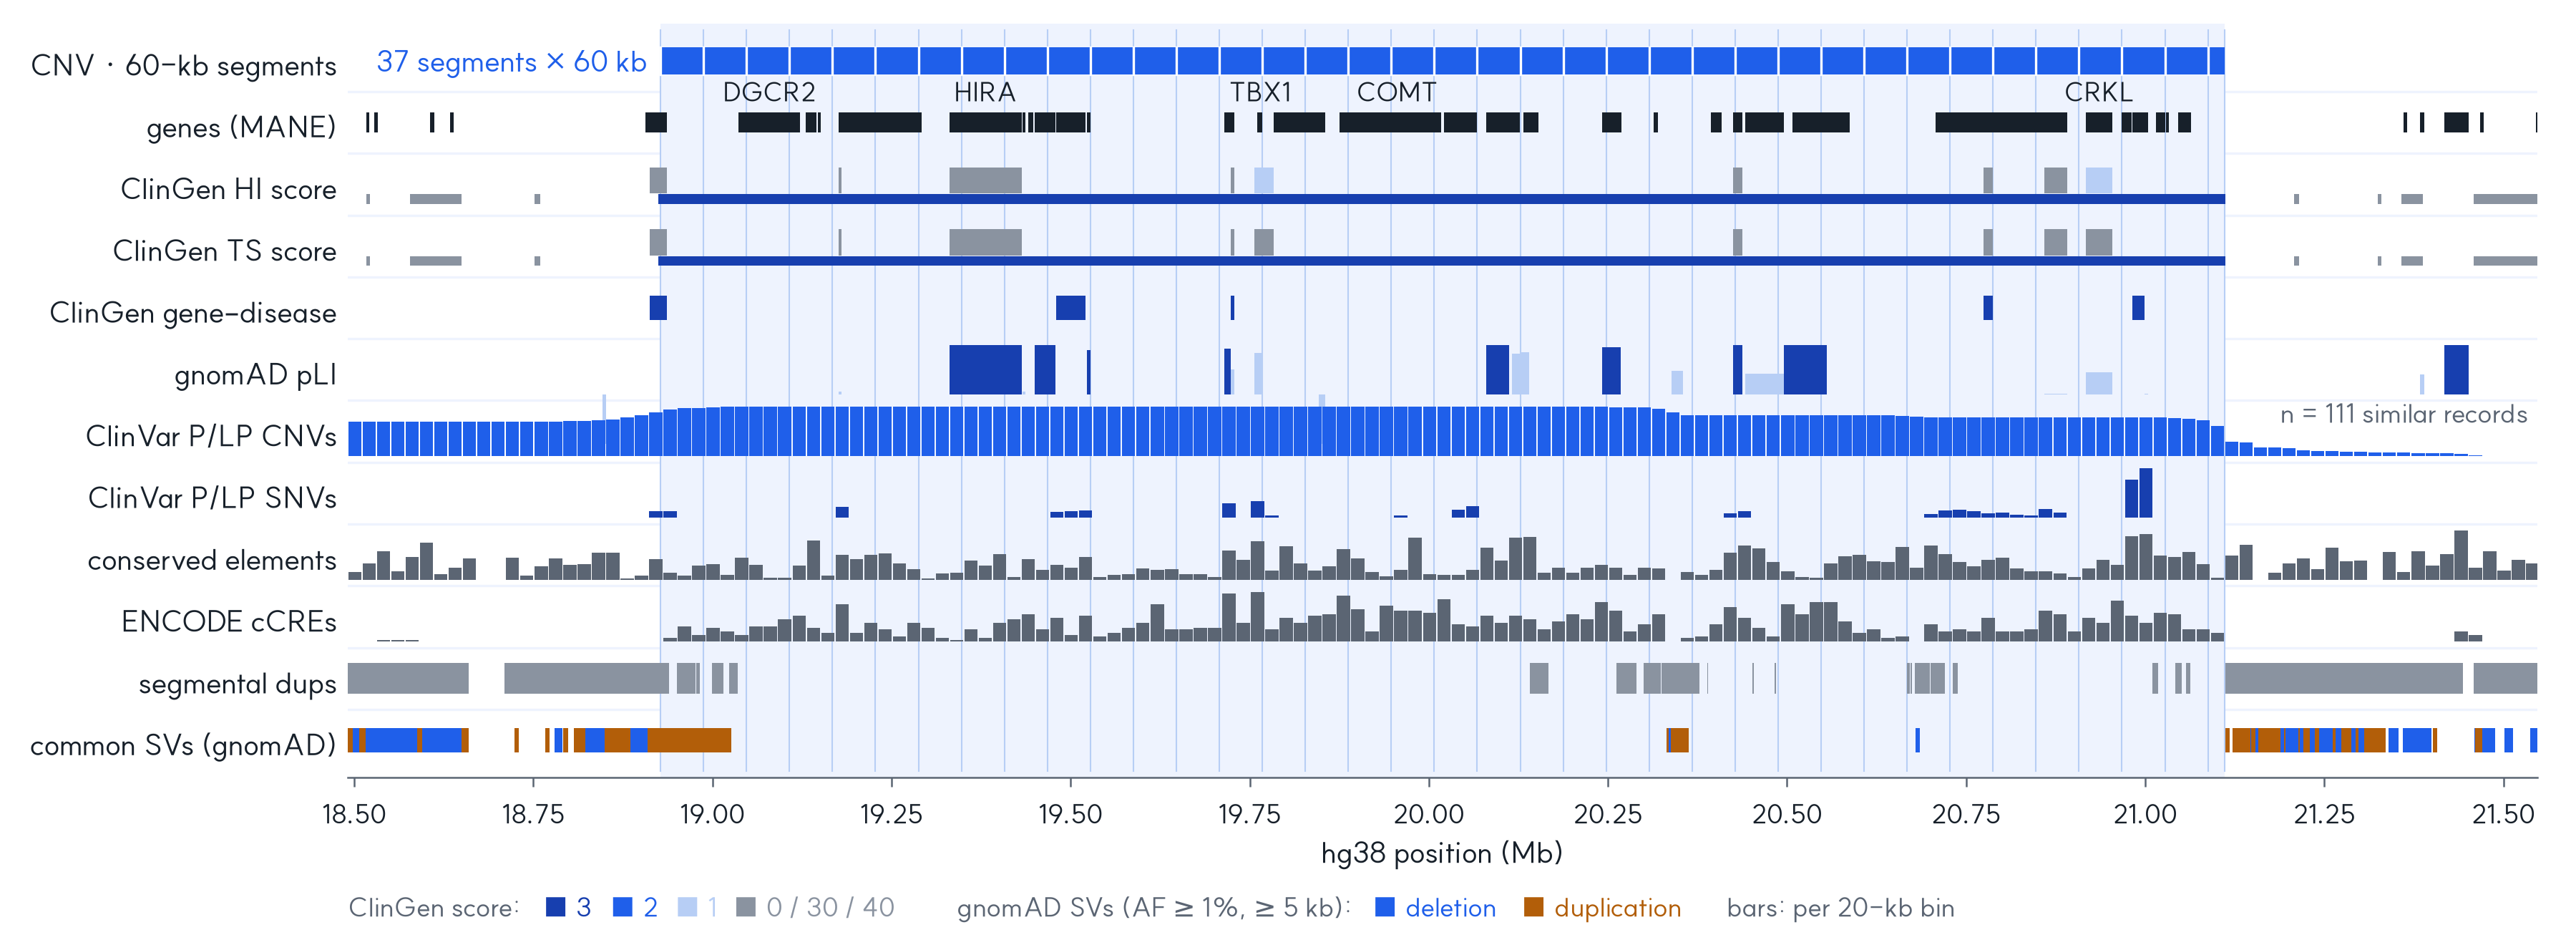

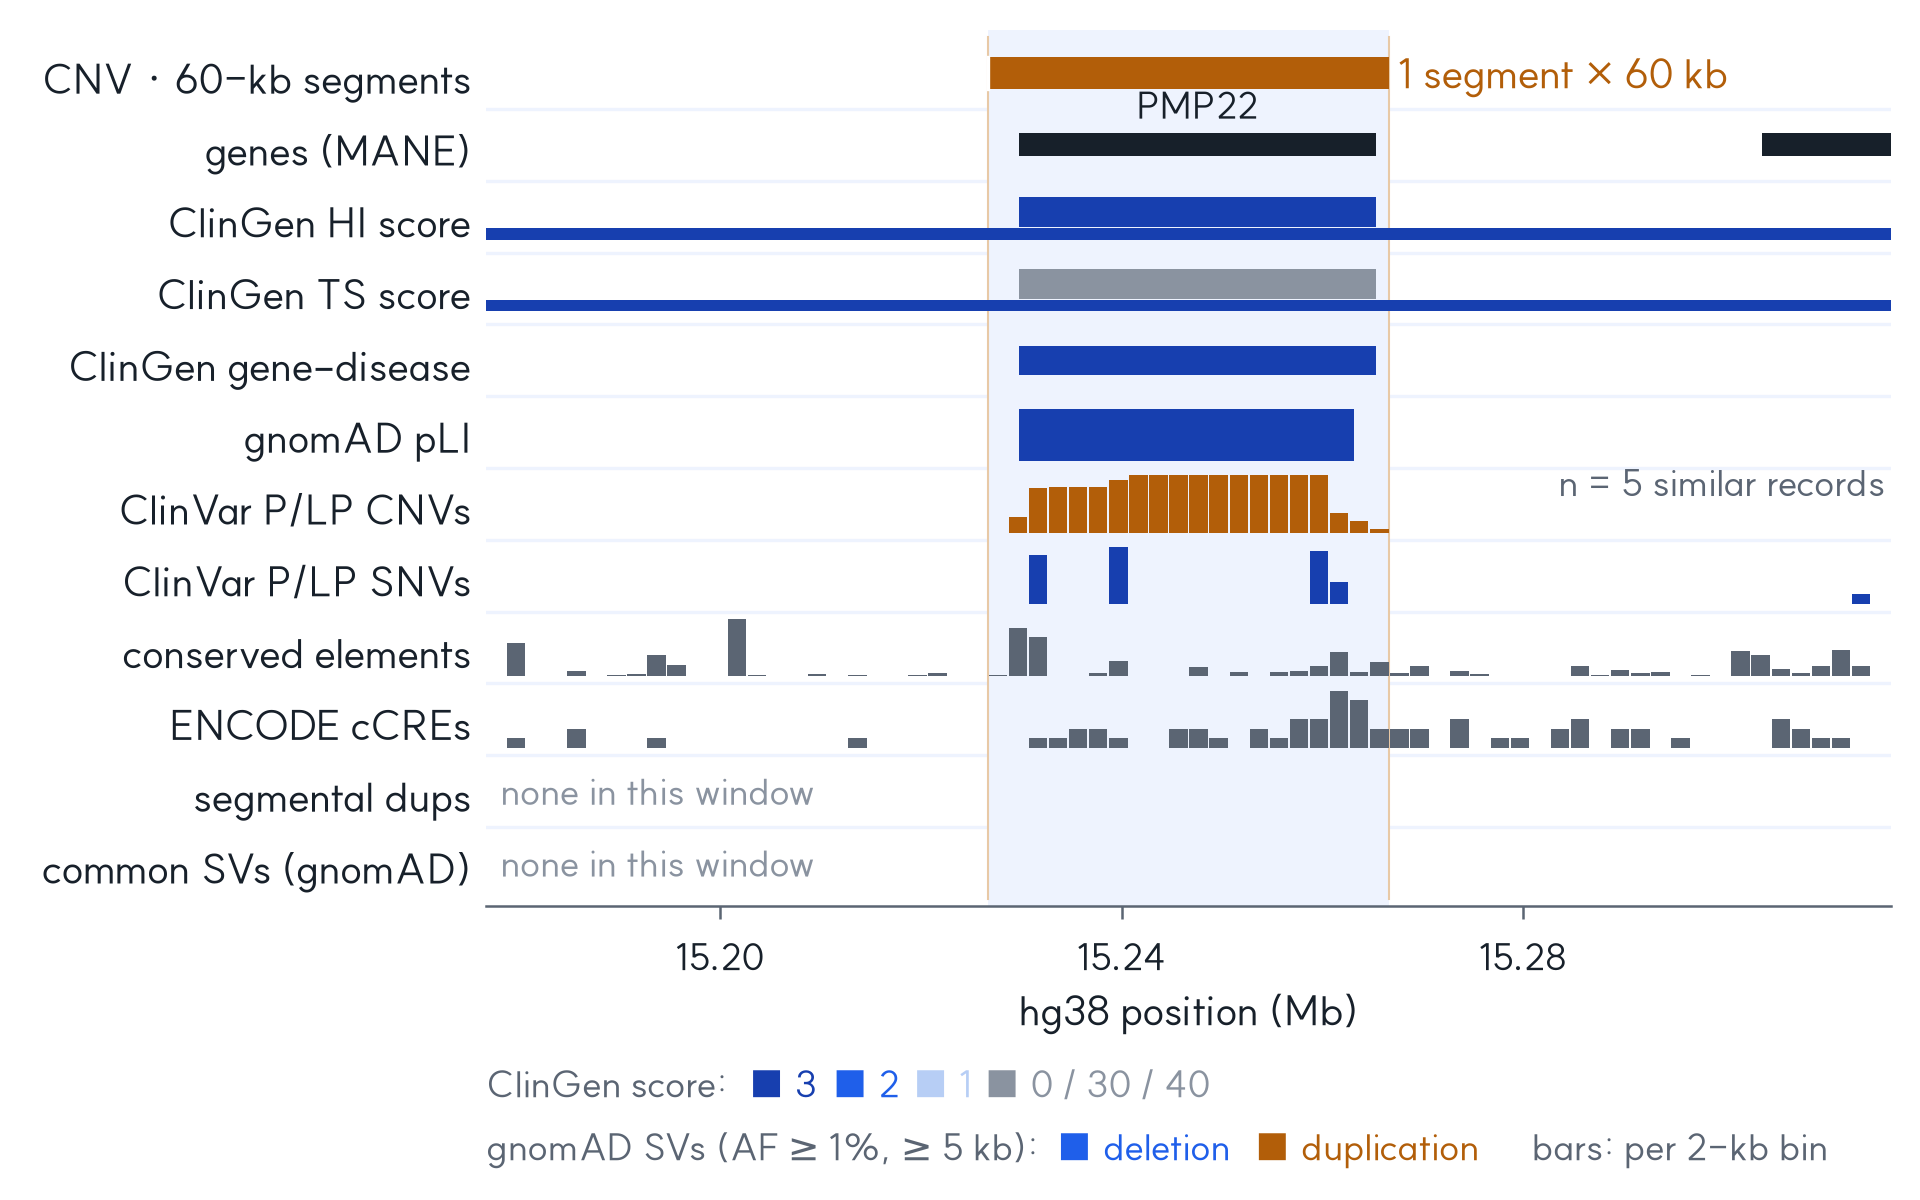

In [35]:
# Slide figures: track panels for P1's 22q11.2 deletion and for the PMP22 duplication (hg38, with the 60-kb segment grid)
def region_tracks(chrom, x0, x1, cnv_type, cnv_iv):
    sub = lambda d: d[(d.chrom == chrom) & (d.chromStart < x1) & (d.chromEnd > x0)].drop_duplicates(["chromStart", "chromEnd", "name"])
    want = ("copy number loss", "deletion") if cnv_type == "DEL" else ("copy number gain", "duplication")
    cvc = sub(TR["clinvarCnv"])
    cvc = cvc[cvc["type"].str.lower().isin(want) & cvc.clinSign.map(is_plp)]
    cvc = cvc[[reciprocal_overlap(cnv_iv[0], cnv_iv[1], a, b) >= 0.5 for a, b in zip(cvc.chromStart, cvc.chromEnd)]]
    sv = sub(TR["gnomadStructuralVariants"])
    sv = sv[sv.svtype.isin(["DEL", "DUP"]) & (pd.to_numeric(sv.af, errors="coerce") >= 0.01) & (sv.chromEnd - sv.chromStart >= 5000)]
    g = genes38[(genes38.chrom == chrom) & (genes38.start0 < x1) & (genes38.end > x0)]
    return {"genes": g, "hi": sub(TR["clinGenHaplo"]), "ts": sub(TR["clinGenTriplo"]), "gd": sub(TR["clinGenGeneDisease"]),
            "pli": sub(TR["pliByGene"]), "clinvar_cnv": cvc, "clinvar_snv": sub(TR["clinvarMain"]),
            "phastcons": sub(TR["phastConsElements100way"]), "ccre": sub(TR["encodeCcreCombined"]),
            "segdup": sub(TR["genomicSuperDups"]), "sv": sv}

def panel_for(cid, figsize, out, label_genes, xtick, decimals, bin_bp, flank_min=50_000):
    c = calls_hg38.set_index("cnv_id").loc[cid]
    fl = max(int(0.2 * c.size38), flank_min)
    x0, x1 = int(c.start38 - fl), int(c.end38 + fl)
    sg = seg_grid[seg_grid.cnv_id == cid]
    n = len(sg)
    trk = region_tracks(c.chrom38, x0, x1, c["type"], (c.start38, c.end38))
    fig = F.fig_tracks((x0, x1), (c.start38, c.end38), c["type"], list(zip(sg.seg_start, sg.seg_end)), trk, out, figsize,
                       label_genes=label_genes, bin_bp=bin_bp, xtick=xtick, decimals=decimals,
                       seg_label=f"{n} segment{'s' if n > 1 else ''} × 60 kb", n_similar=len(trk["clinvar_cnv"]))
    print(cid, "layout problems:", F.layout_problems(fig)); plt.close(fig)

panel_for("P1_22q11_DEL", (12.0, 4.4), f"{FIG}/p2_fig_tracks_22q11.png", ["DGCR2", "HIRA", "TBX1", "COMT", "CRKL"],
          0.25e6, 2, 20_000)
panel_for("P2_PMP22_DUP", (6.4, 4.0), f"{FIG}/p2_fig_tracks_pmp22.png", ["PMP22"], 0.04e6, 2, 2_000)
display(Image(f"{FIG}/p2_fig_tracks_22q11.png", width=1000))
display(Image(f"{FIG}/p2_fig_tracks_pmp22.png", width=560))

channels: 13 | windows: 80 | layout problems: []


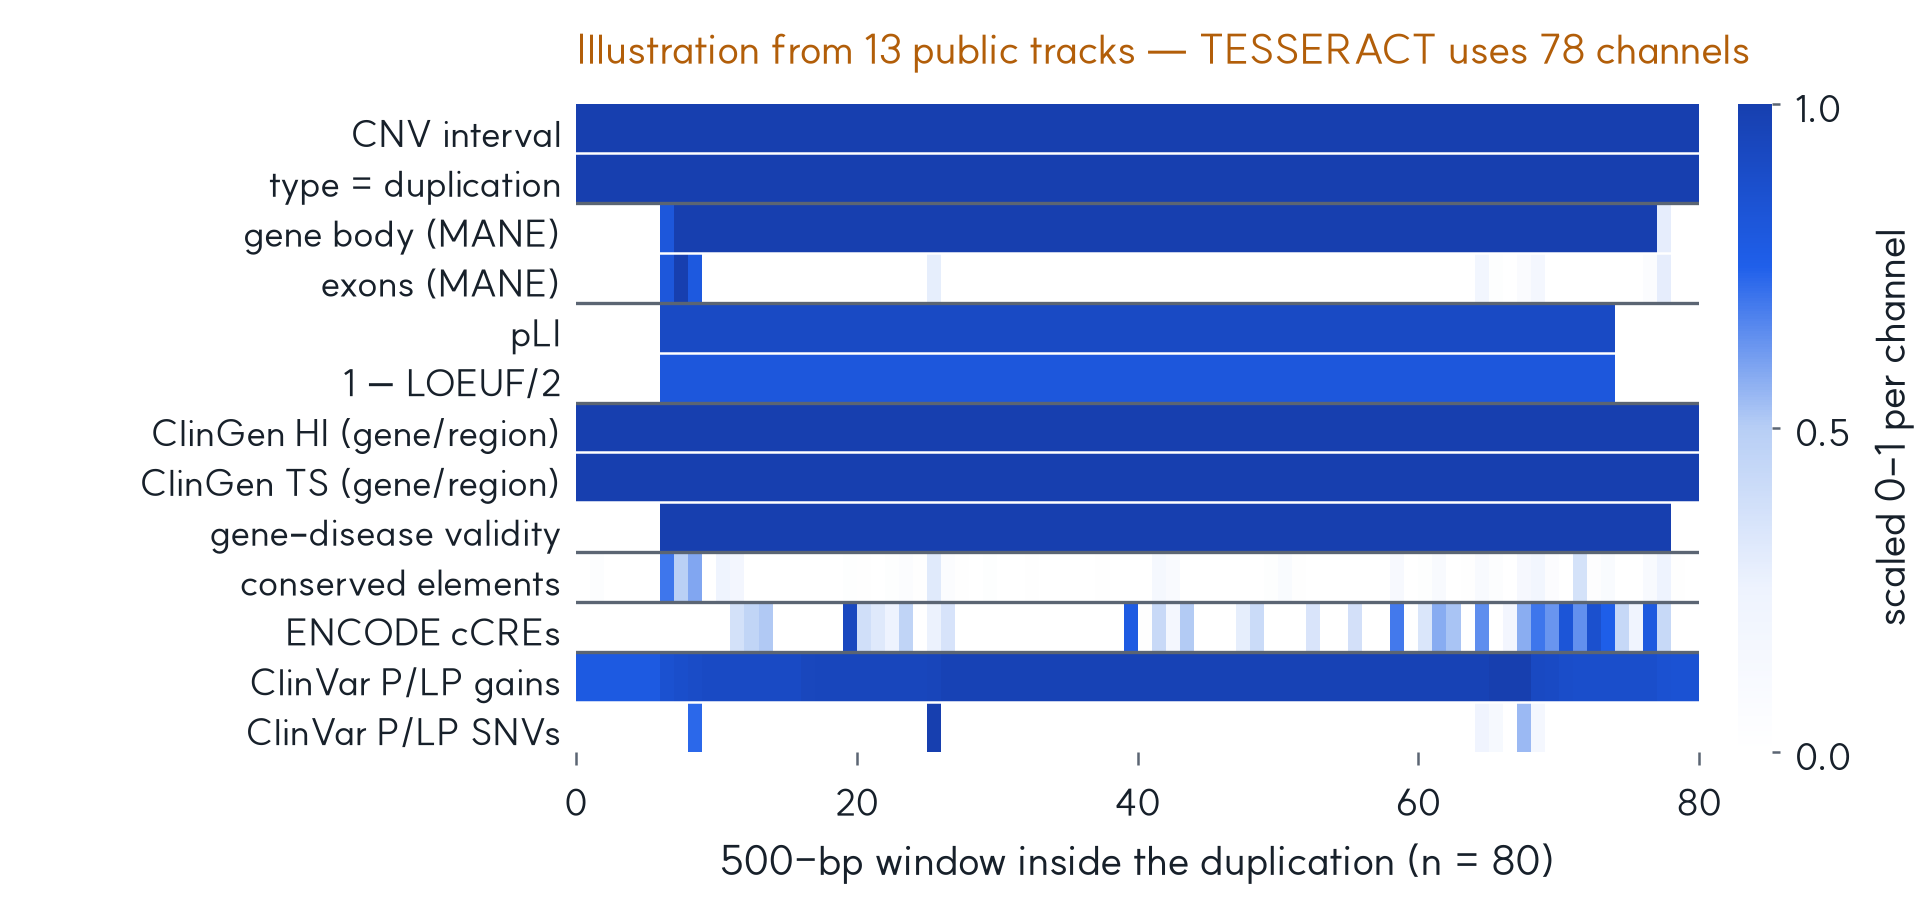

In [36]:
# Illustration: a TESSERACT-style image (channels x 500-bp windows) for the PMP22 duplication, from public tracks only
c = calls_hg38.set_index("cnv_id").loc["P2_PMP22_DUP"]
chrom, s0, e = c.chrom38, int(c.start38), int(c.end38)
edges = np.arange(s0, e + WINDOW, WINDOW); edges[-1] = min(edges[-1], e)
nW = len(edges) - 1
mane = TR["mane"][(TR["mane"].chrom == chrom) & (TR["mane"].chromStart < e) & (TR["mane"].chromEnd > s0)].drop_duplicates("name")

def frac_covered(ivs):
    v = np.zeros(nW)
    for a, b in ivs:
        for i in range(max(0, (a - s0) // WINDOW), min(nW, (b - s0) // WINDOW + 1)):
            v[i] += max(0, min(b, edges[i + 1]) - max(a, edges[i])) / (edges[i + 1] - edges[i])
    return np.clip(v, 0, 1)

def max_score(df, col, scale):
    v = np.zeros(nW)
    for _, r in ov(df, chrom, s0, e).iterrows():
        val = scale(r[col])
        i0, i1 = max(0, (r.chromStart - s0) // WINDOW), min(nW - 1, (r.chromEnd - s0) // WINDOW)
        v[i0:i1 + 1] = np.maximum(v[i0:i1 + 1], val)
    return v

exons = []
for _, r in mane.iterrows():
    for size, st in zip(str(r.blockSizes).strip(",").split(","), str(r.chromStarts).strip(",").split(",")):
        exons.append((r.chromStart + int(st), r.chromStart + int(st) + int(size)))
dos = lambda x: {3: 1.0, 2: 0.67, 1: 0.33}.get(int(x) if str(x).isdigit() else 0, 0.0)
gdv = lambda x: {"Definitive": 1.0, "Strong": 0.8, "Moderate": 0.6, "Limited": 0.3}.get(x, 0.0)
cvc = ov(TR["clinvarCnv"], chrom, s0, e)
cvc = cvc[cvc["type"].str.lower().isin(["copy number gain", "duplication"]) & cvc.clinSign.map(is_plp)]
cov = np.zeros(nW)
for a, b in zip(cvc.chromStart, cvc.chromEnd):
    cov += frac_covered([(a, b)])
snv = ov(TR["clinvarMain"], chrom, s0, e)
snv_counts = np.bincount(np.clip((snv.chromStart.values - s0) // WINDOW, 0, nW - 1), minlength=nW).astype(float)
channels = [
    ("CNV interval", "Variant identity", np.ones(nW)),
    ("type = duplication", "Variant identity", np.ones(nW)),
    ("gene body (MANE)", "Gene structure", frac_covered(zip(mane.chromStart, mane.chromEnd))),
    ("exons (MANE)", "Gene structure", frac_covered(exons)),
    ("pLI", "Gene constraint", max_score(TR["pliByGene"], "_pli", float)),
    ("1 − LOEUF/2", "Gene constraint", max_score(TR["pliByGene"], "_loeuf", lambda x: max(0.0, 1 - float(x) / 2))),
    ("ClinGen HI (gene/region)", "Dosage sensitivity", max_score(TR["clinGenHaplo"], "haploScore", dos)),
    ("ClinGen TS (gene/region)", "Dosage sensitivity", max_score(TR["clinGenTriplo"], "triploScore", dos)),
    ("gene–disease validity", "Dosage sensitivity", max_score(TR["clinGenGeneDisease"], "Classification", gdv)),
    ("conserved elements", "Conservation", frac_covered(zip(*[ov(TR["phastConsElements100way"], chrom, s0, e)[k] for k in ("chromStart", "chromEnd")]))),
    ("ENCODE cCREs", "Regulatory elements", frac_covered(zip(*[ov(TR["encodeCcreCombined"], chrom, s0, e)[k] for k in ("chromStart", "chromEnd")]))),
    ("ClinVar P/LP gains", "Known pathogenic", cov / cov.max() if cov.max() > 0 else cov),
    ("ClinVar P/LP SNVs", "Known pathogenic", snv_counts / snv_counts.max() if snv_counts.max() > 0 else snv_counts),
]
M = np.vstack([ch[2] for ch in channels])
fig = F.fig_tesseract_image(M, [ch[0] for ch in channels], [ch[1] for ch in channels], edges, f"{FIG}/p2_fig_tesseract_image.png")
print("channels:", M.shape[0], "| windows:", M.shape[1], "| layout problems:", F.layout_problems(fig)); plt.close(fig)
display(Image(f"{FIG}/p2_fig_tesseract_image.png", width=560))

In [37]:
# CHECK · the tracks agree with what we expect at these well-known loci
ts = track_sum
hi_p1 = [d for d in ts.loc["P1_22q11_DEL", "ClinGen HI"] if d["kind"] == "region" and d["score"] == 3]
assert any("ISCA-37446" in d["item"] and d["covered"] >= 0.95 for d in hi_p1), "P1 should cover the 22q11.2 (DGS) HI-3 region"
assert any(d["score"] == 3 and d["named gene"] == "PMP22" and d["named gene inside CNV"] for d in ts.loc["P2_PMP22_DUP", "ClinGen TS"])
for cid in ts.index:
    for kind in ("ClinGen HI", "ClinGen TS"):
        for d in ts.loc[cid, kind]:
            if d["score"] == 3 or d["item"] in ("PMP22", "TBX1", "CRKL"):
                print(f"{cid:16s} {kind}: {d['item'][:70]:70s} score {d['score']}  covered {d['covered']:.1%}")
assert ts.loc["P2_UGT2B17_DEL", "DGV Gold max frequency (same type, RO>=50%)"] > 0.05
print(ts[["ClinVar P/LP same-type CNVs (RO>=50%)", "ClinVar P/LP SNVs/indels inside", "gnomAD SV max AF (same type, RO>=50%)",
          "DGV Gold max frequency (same type, RO>=50%)", "segdup fraction"]].to_string())

P1_22q11_DEL     ClinGen HI: ISCA-37446 (22q11.2 recurrent (DGS) region (proximal, A-B, A-C, or A-D score 3  covered 99.8%
P1_22q11_DEL     ClinGen HI: TBX1                                                                   score 1  covered 100.0%
P1_22q11_DEL     ClinGen HI: CRKL                                                                   score 1  covered 100.0%
P1_22q11_DEL     ClinGen TS: ISCA-37446 (22q11.2 recurrent (DGS) region (proximal, A-B, A-C, or A-D score 3  covered 99.8%
P1_22q11_DEL     ClinGen TS: TBX1                                                                   score 0  covered 100.0%
P1_22q11_DEL     ClinGen TS: CRKL                                                                   score 0  covered 100.0%
P2_PMP22_DUP     ClinGen HI: ISCA-37436 (17p12 recurrent (HNPP/CMT1A) region (includes PMP22))      score 3  covered 3.0%
P2_PMP22_DUP     ClinGen HI: PMP22                                                                  score 3  covered 100.0%
P2_PMP22_DUP

**What changed?** hg38 intervals → a table of overlapping annotation, two browser-style track panels with the 60-kb segment
grid, and an **illustrative** TESSERACT-style image (13 public channels; the real model uses 78 channels).

### Discussion

1. **Which tracks would drive a score, and where?** For P1: the ClinGen HI-3 region (22q11.2 DGS region) and the genes in
   the middle segments (TBX1 at about 19.75 Mb, CRKL at about 20.9 Mb), then conservation and cCREs. For PMP22: the whole
   duplication is a single 40-kb segment containing the full PMP22 gene, which has HI 3, sits inside the TS-3 CMT1A region
   and has Definitive gene–disease validity. Read the levels carefully: the *gene-level* ClinGen TS score of PMP22 is 0,
   because when it was curated (2012) no duplication of PMP22 *alone* had been published; the TS-3 curation is attached to
   the 17p12 CMT1A region. A PMP22-only duplication such as P2's is exactly the case where you must read the curation and
   the literature instead of matching numbers.
2. **Circularity.** ClinGen dosage scores and ClinVar records are **model inputs** *and* evidence in the ACMG/ClinGen CNV
   standards. If you count a high TESSERACT score **and** the ClinGen HI score as two independent lines, you count the same
   information twice.
3. **What the model does not see:** population SV frequency (excluded on purpose), inheritance (de novo vs inherited),
   the phenotype, and our RNA data.
4. **UGT2B17** – the deletion removes a whole gene, yet it is common (in the table above: gnomAD SV allele frequency
   ≈ 0.35, DGV Gold up to 16 %; homozygous deletions are frequent in healthy people) and ClinVar lists it as benign.
   Losing a gene is not automatically harmful.
5. **Breakpoints in LCRs and size > 1 Mbp.** P1's and P3's ends lie in segmental duplications: exact breakpoints are uncertain
   in both builds, and the CNVs exceed the model's 1-Mbp design range, so the segmented maximum is used.

**Your turn.** P3's distal deletion overlaps two ClinVar records with exactly the same hg19 coordinates – one *Pathogenic*,
one *Uncertain significance*. Which additional information would help most to decide?

<details><summary>Answer</summary>

**Inheritance**: test the parents. Distal 22q11.2 deletions are often inherited from a mildly affected or unaffected parent
(variable penetrance), and a de novo deletion weighs differently. Also: detailed phenotype comparison with published cases,
the exact gene content (does it include CRKL, and how much of the HI-scored distal region?), and population frequency.
</details>

## Step 8 · Integrate the evidence – one table per CNV  *(4 min)*

### Why this step

A classification needs **all** evidence lines side by side, each with its source. The "evidence direction" column below is a
teaching aid computed with simple, transparent rules (printed in the cell). It is **not** a classification. Formal scoring
uses the **ACMG/ClinGen technical standards for CNVs** (Riggs et al., *Genet Med* 2020;22:245–257) and the
**ClinGen CNV Pathogenicity Calculator** (https://cnvcalc.clinicalgenome.org/cnvcalc/).

In [38]:
# Step 8 · evidence table per CNV (direction = transparent rule of thumb, NOT a classification)
def direction_dosage(c, ts):
    # DEL -> ClinGen HI, DUP -> ClinGen TS. Score 3 = sufficient evidence for dosage sensitivity.
    kind = "HI" if c["type"] == "DEL" else "TS"
    items = [d for d in (ts["ClinGen HI"] if c["type"] == "DEL" else ts["ClinGen TS"]) if d["score"] == 3]
    full = [d for d in items if d["covered"] >= 0.95]
    named = [d for d in items if d["covered"] < 0.95 and d["named gene inside CNV"]]
    if full:
        return f"towards pathogenic (score-3 {kind} item {'fully' if full[0]['covered'] >= 0.999 else '≥ 95%'} inside)"
    if named:
        gname = named[0]["named gene"]
        own = [d["score"] for d in (ts["ClinGen HI"] if c["type"] == "DEL" else ts["ClinGen TS"]) if d["item"] == gname]
        note = f"; but {gname}'s own gene-level {kind} score is {own[0]} - read the curation" if own and own[0] != 3 else ""
        return f"towards pathogenic (contains {gname}, the gene named in a score-3 {kind} region{note})"
    if items:
        return f"uncertain (partial overlap with a score-3 {kind} region)"
    return "neutral (no score-3 dosage item)"

def clinvar_direction(ts):
    plp, vus, ben = (ts["ClinVar P/LP same-type CNVs (RO>=50%)"], ts["ClinVar VUS/conflicting (RO>=50%)"],
                     ts["ClinVar benign same-type CNVs (RO>=50%)"])
    if plp and not (vus or ben):
        return "towards pathogenic (similar P/LP records)"
    if plp and plp >= 2 * (vus + ben):
        return "mostly towards pathogenic (some VUS/benign records)"
    if plp:
        return "conflicting records"
    if ben and not vus:
        return "towards benign (similar benign records)"
    if vus or ben:
        return "uncertain (VUS/benign records only)"
    return "neutral (no similar record)"

def evidence_table(cid):
    c = calls_hg38.set_index("cnv_id").loc[cid]
    ts = track_sum.loc[cid]
    lt = lift.set_index("cnv_id").loc[cid]
    rs = rna_summary.set_index("cnv_id").loc[cid]
    gt = gene_tables[cid]
    n_genes = len(lt["_g38"])
    gene_thr = 25 if c["type"] == "DEL" else 35
    hi_txt = "; ".join(f"{d['item']} {d['score']} ({d['overlap']})" for d in (ts["ClinGen HI"] if c["type"] == "DEL" else ts["ClinGen TS"])
                       if d["score"] in (1, 2, 3)) or "none with score 1-3"
    pop = max(ts["gnomAD SV max AF (same type, RO>=50%)"], ts["DGV Gold max frequency (same type, RO>=50%)"])
    exp = np.log2(c.cn / 2) if c.cn > 0 else None
    med = rs["median log2FC (expressed)"]
    if rs["expressed"] == 0:
        rna_dir = "uninformative (no expressed gene)"
    elif c.cn == 0:
        rna_dir = "supports the call (no RNA)" if gt[gt.expressed]["patient CPM"].max() < 0.5 else "conflicts with the call"
    else:
        rna_dir = "supports a dosage effect (not pathogenicity)" if abs(med - exp) <= 0.4 else "weak/unclear dosage effect"
    rows = [
        ("DNA read depth (hg19)", f"CN {c.cn}, mean log2 {c.log2:+.2f}, {c.n_bins} bins, {c.size_kb:,.0f} kb", "technical: CNV present"),
        ("Coordinates", f"hg19 {lt['hg19']} -> hg38 {lt['(b) breakpoint lift']}", "technical"),
        ("Liftover check", f"{lt['(a) pieces']} CrossMap piece(s); genes only in hg19: {lt['only hg19'] or 'none'}",
         "caution: breakpoints in segmental duplications" if ts["segdup fraction"] > 0.05 or lt["only hg19"] else "technical: OK"),
        ("Protein-coding genes (hg38 MANE)", f"{n_genes}: " + ", ".join(lt["_g38"][:8]) + (" …" if n_genes > 8 else ""),
         f"towards pathogenic (≥ {gene_thr} genes)" if n_genes >= gene_thr else "neutral (gene number)"),
        ("Dosage-sensitive genes/regions (ClinGen)", hi_txt, direction_dosage(c, ts)),
        ("Matched RNA (synthetic)", f"{rs['expressed']}/{rs['genes']} genes expressed; median log2FC {med}", rna_dir),
        ("Population frequency (gnomAD SV, DGV Gold)", f"max {pop:.1%} (same type, ≥ 50% reciprocal overlap)",
         "towards benign (common, ≥ 1%)" if pop >= 0.01 else "neutral (rare or absent)"),
        ("ClinVar CNVs (same type, RO ≥ 50%)", f"{ts['ClinVar P/LP same-type CNVs (RO>=50%)']} P/LP, "
         f"{ts['ClinVar VUS/conflicting (RO>=50%)']} VUS/conflicting, {ts['ClinVar benign same-type CNVs (RO>=50%)']} benign"
         + (f"; e.g. {', '.join(ts['ClinVar examples'][:3])}" if ts["ClinVar examples"] else ""), clinvar_direction(ts)),
        ("TESSERACT-CNV score", "not run (adapter not configured)" if tess_scores is None
         else str(tess_scores.set_index("cnv_id").score.get(cid, "missing")), "not available" if tess_scores is None else "model output (do not double count ClinGen/ClinVar)"),
        ("Inheritance / phenotype", "parents not tested; phenotype in Step 0", "not assessed (needs parental testing and clinical review)"),
    ]
    return pd.DataFrame(rows, columns=["evidence", "value", "evidence direction"])

evidence = {cid: evidence_table(cid) for cid in calls_hg38.cnv_id}
for cid, t in evidence.items():
    print(f"\n=== {cid}")
    with pd.option_context("display.max_colwidth", 110):
        display(t)


=== P1_22q11_DEL


,evidence,value,evidence direction
0,DNA read depth (hg19),"CN 1, mean log2 -0.99, 433 bins, 2,550 kb",technical: CNV present
1,Coordinates,"hg19 chr22:18,915,001-21,465,000 -> hg38 chr22:18,927,488-21,110,711",technical
2,Liftover check,"117 CrossMap piece(s); genes only in hg19: ['FAM246B', 'FAM246C', 'GGTLC3', 'RIMBP3', 'TMEM191B']",caution: breakpoints in segmental duplications
3,Protein-coding genes (hg38 MANE),"43: AIFM3, ARVCF, C22orf39, CCDC188, CDC45, CLDN5, CLTCL1, COMT …",towards pathogenic (≥ 25 genes)
4,Dosage-sensitive genes/regions (ClinGen),"ISCA-37446 (22q11.2 recurrent (DGS) region (proximal, A-B, A-C, or A-D) (includes TBX1)) 3 (near-complete ...",towards pathogenic (score-3 HI item ≥ 95% inside)
5,Matched RNA (synthetic),32.0/43.0 genes expressed; median log2FC -0.85,supports a dosage effect (not pathogenicity)
6,"Population frequency (gnomAD SV, DGV Gold)","max 0.0% (same type, ≥ 50% reciprocal overlap)",neutral (rare or absent)
7,"ClinVar CNVs (same type, RO ≥ 50%)","111 P/LP, 5 VUS/conflicting, 0 benign; e.g. VCV004796185 (Pathogenic, RO 1.00), VCV004820057 (Pathogenic, ...",mostly towards pathogenic (some VUS/benign records)
8,TESSERACT-CNV score,not run (adapter not configured),not available
9,Inheritance / phenotype,parents not tested; phenotype in Step 0,not assessed (needs parental testing and clinical review)



=== P2_PMP22_DUP


,evidence,value,evidence direction
0,DNA read depth (hg19),"CN 3, mean log2 +0.55, 8 bins, 40 kb",technical: CNV present
1,Coordinates,"hg19 chr17:15,130,001-15,170,000 -> hg38 chr17:15,226,684-15,266,683",technical
2,Liftover check,1 CrossMap piece(s); genes only in hg19: none,technical: OK
3,Protein-coding genes (hg38 MANE),1: PMP22,neutral (gene number)
4,Dosage-sensitive genes/regions (ClinGen),ISCA-37436 (17p12 recurrent (HNPP/CMT1A) region (includes PMP22)) 3 (partial (3%)),"towards pathogenic (contains PMP22, the gene named in a score-3 TS region; but PMP22's own gene-level TS s..."
5,Matched RNA (synthetic),1.0/1.0 genes expressed; median log2FC 0.55,supports a dosage effect (not pathogenicity)
6,"Population frequency (gnomAD SV, DGV Gold)","max 0.0% (same type, ≥ 50% reciprocal overlap)",neutral (rare or absent)
7,"ClinVar CNVs (same type, RO ≥ 50%)","5 P/LP, 0 VUS/conflicting, 0 benign; e.g. VCV004082242 (Pathogenic, RO 0.89), VCV000660675 (Pathogenic, RO...",towards pathogenic (similar P/LP records)
8,TESSERACT-CNV score,not run (adapter not configured),not available
9,Inheritance / phenotype,parents not tested; phenotype in Step 0,not assessed (needs parental testing and clinical review)



=== P2_UGT2B17_DEL


,evidence,value,evidence direction
0,DNA read depth (hg19),"CN 1, mean log2 -1.08, 19 bins, 110 kb",technical: CNV present
1,Coordinates,"hg19 chr4:69,375,001-69,485,000 -> hg38 chr4:68,509,283-68,619,282",technical
2,Liftover check,1 CrossMap piece(s); genes only in hg19: none,caution: breakpoints in segmental duplications
3,Protein-coding genes (hg38 MANE),1: UGT2B17,neutral (gene number)
4,Dosage-sensitive genes/regions (ClinGen),none with score 1-3,neutral (no score-3 dosage item)
5,Matched RNA (synthetic),1.0/1.0 genes expressed; median log2FC -0.37,weak/unclear dosage effect
6,"Population frequency (gnomAD SV, DGV Gold)","max 35.0% (same type, ≥ 50% reciprocal overlap)","towards benign (common, ≥ 1%)"
7,"ClinVar CNVs (same type, RO ≥ 50%)","0 P/LP, 0 VUS/conflicting, 5 benign; e.g. VCV000147015 (Benign, RO 0.98), VCV000146955 (Benign, RO 0.98), ...",towards benign (similar benign records)
8,TESSERACT-CNV score,not run (adapter not configured),not available
9,Inheritance / phenotype,parents not tested; phenotype in Step 0,not assessed (needs parental testing and clinical review)



=== P3_22q11_DEL


,evidence,value,evidence direction
0,DNA read depth (hg19),"CN 1, mean log2 -0.99, 211 bins, 1,450 kb",technical: CNV present
1,Coordinates,"hg19 chr22:21,030,001-22,480,000 -> hg38 chr22:20,675,713-22,125,606",technical
2,Liftover check,97 CrossMap piece(s); genes only in hg19: none,caution: breakpoints in segmental duplications
3,Protein-coding genes (hg38 MANE),"24: AIFM3, CCDC116, CRKL, FAM246A, HIC2, LRRC74B, LZTR1, MAPK1 …",neutral (gene number)
4,Dosage-sensitive genes/regions (ClinGen),"ISCA-37446 (22q11.2 recurrent (DGS) region (proximal, A-B, A-C, or A-D) (includes TBX1)) 3 (partial (20%))...",uncertain (partial overlap with a score-3 HI region)
5,Matched RNA (synthetic),19.0/24.0 genes expressed; median log2FC -0.8,supports a dosage effect (not pathogenicity)
6,"Population frequency (gnomAD SV, DGV Gold)","max 0.0% (same type, ≥ 50% reciprocal overlap)",neutral (rare or absent)
7,"ClinVar CNVs (same type, RO ≥ 50%)","4 P/LP, 1 VUS/conflicting, 0 benign; e.g. VCV000057332 (Pathogenic, RO 0.67), VCV000150486 (Pathogenic, RO...",mostly towards pathogenic (some VUS/benign records)
8,TESSERACT-CNV score,not run (adapter not configured),not available
9,Inheritance / phenotype,parents not tested; phenotype in Step 0,not assessed (needs parental testing and clinical review)



=== P3_UGT2B17_DEL


,evidence,value,evidence direction
0,DNA read depth (hg19),"CN 0, mean log2 -2.93, 19 bins, 110 kb",technical: CNV present
1,Coordinates,"hg19 chr4:69,375,001-69,485,000 -> hg38 chr4:68,509,283-68,619,282",technical
2,Liftover check,1 CrossMap piece(s); genes only in hg19: none,caution: breakpoints in segmental duplications
3,Protein-coding genes (hg38 MANE),1: UGT2B17,neutral (gene number)
4,Dosage-sensitive genes/regions (ClinGen),none with score 1-3,neutral (no score-3 dosage item)
5,Matched RNA (synthetic),1.0/1.0 genes expressed; median log2FC -3.75,supports the call (no RNA)
6,"Population frequency (gnomAD SV, DGV Gold)","max 35.0% (same type, ≥ 50% reciprocal overlap)","towards benign (common, ≥ 1%)"
7,"ClinVar CNVs (same type, RO ≥ 50%)","0 P/LP, 0 VUS/conflicting, 5 benign; e.g. VCV000147015 (Benign, RO 0.98), VCV000146955 (Benign, RO 0.98), ...",towards benign (similar benign records)
8,TESSERACT-CNV score,not run (adapter not configured),not available
9,Inheritance / phenotype,parents not tested; phenotype in Step 0,not assessed (needs parental testing and clinical review)


In [39]:
# CHECK · every CNV has all evidence lines; nothing was auto-classified and no model score was invented
for cid, t in evidence.items():
    assert len(t) == 10 and (t["evidence direction"].str.len() > 0).all()
    assert not t["evidence direction"].str.match(r"(?i)^(pathogenic|likely pathogenic|benign|likely benign|vus)").any()
assert (tess_scores is None) == (TESSERACT_CMD is None)
print("evidence lines (towards pathogenic / towards benign) per CNV:",
      {cid: (int(t["evidence direction"].str.contains("towards pathogenic").sum()),
             int(t["evidence direction"].str.contains("towards benign").sum())) for cid, t in evidence.items()})

evidence lines (towards pathogenic / towards benign) per CNV: {'P1_22q11_DEL': (3, 0), 'P2_PMP22_DUP': (2, 0), 'P2_UGT2B17_DEL': (0, 2), 'P3_22q11_DEL': (1, 0), 'P3_UGT2B17_DEL': (0, 2)}


**What changed?** Every result of Steps 1–7 is now in one table per CNV, with its source and a direction. Nothing is
auto-classified: you would take these lines to the ClinGen CNV calculator and score them by the 2020 standards.

**Discussion.** (1) For P1 and P2, which single evidence line would you trust most, and why? (2) For P3, what is missing
before a classification is possible? (3) P2 has two CNVs – how do you report a common, benign UGT2B17 deletion next to a
pathogenic PMP22 duplication?

**Your turn.** Why should a high TESSERACT score and a ClinGen HI-3 region **not** be counted as two independent pieces of
evidence?

<details><summary>Answer</summary>

Because ClinGen dosage curation is one of TESSERACT's input channels (and ClinVar records were used to build its training
labels). A high score partly *repeats* the ClinGen evidence; counting both inflates the evidence (circularity). Use the
model as a summary or as a tie-breaker for regions without curation, not as an extra independent line.
</details>

In [40]:
# Write results/p2_results.json (every number shown on the slides comes from here)
def jsonable(x):
    if isinstance(x, (np.integer,)): return int(x)
    if isinstance(x, (np.floating,)): return None if not np.isfinite(x) else float(x)
    if isinstance(x, (np.bool_,)): return bool(x)
    if isinstance(x, (set, tuple)): return [jsonable(v) for v in x]
    if isinstance(x, list): return [jsonable(v) for v in x]
    if isinstance(x, dict): return {str(k): jsonable(v) for k, v in x.items()}
    if isinstance(x, pd.DataFrame): return [jsonable(r) for r in x.to_dict(orient="records")]
    return x

def manifest(root="."):
    out = []
    for d in ["data", "results", "scripts", "fonts"]:
        for dp, dn, fn in os.walk(os.path.join(root, d)):
            if "/bam" in dp or "__pycache__" in dp:
                continue
            for f in sorted(fn):
                p = os.path.join(dp, f)
                out.append({"path": os.path.relpath(p, root), "bytes": os.path.getsize(p)})
    return out

pub_prov = json.load(open("data/provenance_public_data.json"))
results = {
    "description": "Practice 2 (CNVs from reads to interpretation) - results of the executed notebook. SYNTHETIC samples.",
    "generated_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds"),
    "tool_versions": VERSIONS,
    "seed": 20261015,
    "dna_qc": qc.reset_index().to_dict(orient="records"),
    "mapq_segdup_C1": mapq_table.reset_index().rename(columns={"index": "where"}).to_dict(orient="records"),
    "fragments_counted": {k: int(v) for k, v in counts.sum().items()},
    "lcr_mapq_demo_C1_all_vs_mapq20": lcr_demo,
    "pmp22_bin_example": pmp22_bin_example,
    "bins": {"bin_size_bp": 5000, "total": len(bins), "masked_total": int(masked.sum()), "masked_gap": int(mask_gap.sum()),
             "lowdepth_masked_in_segdup_fraction": round(float(in_sd[mask_low].mean()), 3),
             "masked_low_panel_depth": int(mask_low.sum()), "masked_variable_controls": int(mask_var.sum()),
             "sigma0_cn2": round(SIGMA0, 4), "centring_offsets": {k: round(v, 4) for k, v in offset.items()},
             "gc_effect_C1_raw_depth": round(gc_effect_raw, 3), "gc_effect_C1_ratio_to_panel": round(gc_effect_ratio, 3)},
    "worked_examples": worked_examples.to_dict(orient="records"),
    "hmm": {"states": CN_STATES.tolist(), "expected_log2": [round(v, 3) for v in EXPECTED_LOG2], "sigma": [round(v, 4) for v in SIGMA],
            "p_switch": P_SWITCH, "min_bins": MIN_BINS},
    "calls_hg19": calls.to_dict(orient="records"),
    "truth_comparison": truth_cmp.to_dict(orient="records"),
    "false_calls_patients": len(false_calls), "calls_in_control_C1": int((calls["sample"] == "C1").sum()),
    "liftover_calls": [{k: v for k, v in r.items() if not k.startswith("_")} | {"bp_lift_start0": r["_bp_iv"][0], "bp_lift_end": r["_bp_iv"][1],
                        "outer_start0": r["_outer"][0], "outer_end": r["_outer"][1], "genes_hg19": r["_g19"], "genes_hg38": r["_g38"]}
                       for r in lift.to_dict(orient="records")],
    "liftover_unmap_file": unmapped,
    "liftover_public_records": [{k: v for k, v in r.items() if not k.startswith("_")} | {"bp_lift_start0": r["_bp_iv"][0], "bp_lift_end": r["_bp_iv"][1],
                                 "outer_start0": r["_outer"][0], "outer_end": r["_outer"][1]}
                                for r in lift_public.to_dict(orient="records")],
    "public_grch38": {k: {"source": v[0], "start_1based": v[1] + 1, "end": v[2]} for k, v in PUBLIC_GRCH38.items()},
    "gene_differences_between_builds": gene_diff.to_dict(orient="records"),
    "liftover_rule": "breakpoint lift + gene-content check",
    "calls_hg38": tess_in.to_dict(orient="records"),
    "rna_summary": rna_summary.to_dict(orient="records"),
    "rna_key_genes": pd.concat([d[d.gene.isin(KEY_GENES)].assign(cnv_id=cid) for cid, d in gene_tables.items()]).to_dict(orient="records"),
    "rna_genes_per_cnv": {cid: d.to_dict(orient="records") for cid, d in gene_tables.items()},
    "rna_ugt2b17_by_sample": ugt.reset_index().rename(columns={"index": "sample"}).to_dict(orient="records"),
    "wrong_build_demo": wrong_build.to_dict(orient="records"),
    "tesseract": {"input_rows": tess_in.to_dict(orient="records"), "size_check": size_check.to_dict(orient="records"),
                  "segments_per_cnv": seg_grid.groupby("cnv_id").size().to_dict(), "window_bp": WINDOW, "segment_windows": SEG_WINDOWS,
                  "run": tess_scores is not None,
                  "scores": None if tess_scores is None else tess_scores.to_dict(orient="records"),
                  "segment_scores": None if tess_segments is None else tess_segments.to_dict(orient="records")},
    "track_summary": track_sum.reset_index().to_dict(orient="records"),
    "tesseract_group_mapping": groups.to_dict(orient="records"),
    "evidence_tables": {cid: t.to_dict(orient="records") for cid, t in evidence.items()},
    "provenance": {"public_data": pub_prov, "tracks_hg38": {k: v for k, v in track_prov.items() if k != "track_list"}},
    "figures": sorted(os.listdir(FIG)),
}
results["file_manifest"] = manifest()
with open("results/p2_results.json", "w") as fh:
    json.dump(jsonable(results), fh, indent=1, default=str)
print("results/p2_results.json:", round(os.path.getsize("results/p2_results.json") / 1e3), "kB;", len(results["file_manifest"]), "files in manifest")

results/p2_results.json: 123 kB; 79 files in manifest


## Step 9 · Wrap-up  *(2 min)*

| Step | Tool | What changes | How to verify |
|---|---|---|---|
| 1 Map | `minimap2 -ax sr`, `samtools fixmate/sort/markdup/index` | FASTQ → sorted, indexed BAM; duplicates flagged | `flagstat`: > 99.9 % mapped, ≈ 3 % duplicates; low MAPQ in segmental duplications |
| 2 Depth | `pysam` counting, panel of normals | BAM → fragments per 5-kb bin → centred log2 ratio, masked bins | your C1 = panel C1; GC trend gone; normal bins ≈ 0 |
| 3 Call | HMM + Viterbi | log2 ratios → CNV segments (hg19 BED) | all planted CNVs recovered, no calls in C1; breakpoint error ≤ 5 kb outside LCRs |
| 4 Liftover | `CrossMap` + UCSC chain | hg19 BED → hg38 BED (breakpoint lift) | pieces, sizes, `.unmap`, gene content, public GRCh38 records |
| 5 RNA | `pandas` | gene counts → CPM, log2FC, z per CNV gene | median log2FC ≈ −1 / +0.58; CN 0 → no RNA; wrong-build demo |
| 6 TESSERACT input | `pandas`, adapter cell | hg38 BED → model input + 60-kb segment template | 50 bp–1 Mbp size check; segment counts; no invented scores |
| 7 Tracks | UCSC API data | interval → overlapping annotation | ClinGen HI/TS, ClinVar, population, segmental duplications |
| 8 Evidence | – | everything → one table per CNV | each line has a source and a direction; no auto-classification |

### Exit questions

1. A heterozygous deletion gives log2 ≈ −1. Why does a heterozygous duplication give ≈ +0.58 and not +1?
2. Why were the LCR22 bins masked, and what does that mean for the 22q11.2 breakpoints?
3. Name the two checks you use to accept a liftover, and say why ClinVar's GRCh38 interval for VCV000155158 is longer than
   our breakpoint lift.
4. Name two kinds of evidence you used in Step 8 that TESSERACT-CNV does not see.
5. Why is a missing RNA change not evidence against a deletion?

<details><summary>Answers</summary>

1. Three copies instead of two: ratio 3/2 = 1.5 and log2(1.5) ≈ 0.58. +1 would mean 4 copies (ratio 2).
2. Reads from near-identical repeats get MAPQ < 20 and are not counted, so even the controls have almost no usable depth
   there. The breakpoints lie inside these repeats, so short-read depth cannot place them: we report the edge of the
   unique sequence, and exact breakpoints need long reads or other assays.
3. (a) Breakpoint lift gives one interval on the same chromosome with a sensible size; (b) the gene content (unique
   genes) is the same in hg19 and hg38 annotation. ClinVar (NCBI remapping) reports an outer span whose start is the most
   proximal mapped piece inside LCR22A, which is assembled differently in GRCh38.
4. Population SV frequency (gnomAD SV, DGV), inheritance, phenotype, and the matched RNA.
5. The gene may not be expressed in the sampled tissue, its expression may be buffered, or the effect may be smaller than
   the noise of one sample. Absence of signal is uninformative.
</details>

In [41]:
# CHECK · the whole notebook ran; list what was written
print(f"total run time: {time.time() - T_START:.0f} s")
print("slide figures:", sorted(os.listdir(FIG)))
print("results:", sorted(os.listdir("data/results")))

total run time: 24 s
slide figures: ['p2_fig_caller_steps.png', 'p2_fig_cnv_profiles.png', 'p2_fig_liftover.png', 'p2_fig_rna_dosage.png', 'p2_fig_tesseract_image.png', 'p2_fig_tracks_22q11.png', 'p2_fig_tracks_pmp22.png', 'p2_fig_wrong_build.png']
results: ['cnv_calls_hg19.bed', 'cnv_calls_hg19.tsv', 'cnv_calls_hg38.bed', 'liftover_a.log', 'liftover_a_pieces_hg38.bed', 'liftover_a_pieces_hg38.bed.unmap', 'liftover_b.log', 'liftover_b_breakpoints_hg19.bed', 'liftover_b_breakpoints_hg38.bed', 'liftover_b_breakpoints_hg38.bed.unmap', 'planted_breakpoints_hg19.bed', 'planted_breakpoints_hg38.bed', 'planted_breakpoints_hg38.bed.unmap', 'planted_hg19.bed', 'planted_pieces_hg38.bed', 'planted_pieces_hg38.bed.unmap', 'tesseract_input_hg38.tsv', 'tesseract_segments_template_hg38.tsv']
